# PERSIAPAN ENVIRONMENT DAN PENYIMPANAN DATA

In [ ]:
# Menghubungkan Google Colab dengan Google Drive

from google.colab import drive
drive.mount('/content/drive')

# Menentukan folder kerja
import os
from pathlib import Path

FOLDER = Path('/content/drive/MyDrive/EDA_NDR')
FOLDER.mkdir(parents=True, exist_ok=True)

os.chdir(FOLDER)

print("Folder kerja:", os.getcwd())

# Instalasi library secara otomatis jika belum tersedia
import importlib.util
import subprocess
import sys

libraries = {
    'pypdf': 'pypdf',
    'pymupdf': 'pymupdf',
    'openpyxl': 'openpyxl',
    'pandas': 'pandas',
    'numpy': 'numpy',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
    'sklearn': 'scikit-learn'
}

for modul, paket in libraries.items():
    if importlib.util.find_spec(modul) is None:
        subprocess.check_call([
            sys.executable, '-m', 'pip',
            'install', '-q', paket
        ])

# Import seluruh library yang diperlukan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pymupdf as fitz
import unicodedata
import re

from pypdf import PdfReader
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from google.colab import files

# Menentukan file sumber
CSV = FOLDER / 'rekap_ndr_lengkap.csv'

KAMUS = FOLDER / 'Kamus singkatan motor.xlsx'

PDFS = {
    'jul': FOLDER / 'Online Juli.pdf',
    'aug': FOLDER / 'Online Agustus.pdf',
    'sep': FOLDER / 'Online September.pdf',
    'oct': FOLDER / 'Online Oktober.pdf'
}

# Parameter penelitian
MULAI = pd.Timestamp('2026-07-01')
AKHIR = pd.Timestamp('2026-10-31')

REKONSILIASI_LENGKAP_TERVERIFIKASI = False

# Pemeriksaan file
print("\n=== PEMERIKSAAN FILE ===")

for file in [CSV, KAMUS, *PDFS.values()]:
    print(
        file.name,
        ': TERSEDIA' if file.exists()
        else ': TIDAK DITEMUKAN'
    )

print("\nPersiapan environment selesai.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder kerja: /content/drive/MyDrive/EDA_NDR

=== PEMERIKSAAN FILE ===
rekap_ndr_lengkap.csv : TERSEDIA
Kamus singkatan motor.xlsx : TERSEDIA
Online Juli.pdf : TERSEDIA
Online Agustus.pdf : TERSEDIA
Online September.pdf : TERSEDIA
Online Oktober.pdf : TERSEDIA

Persiapan environment selesai.


## **BAB 1 (Pendahuluan & Memahami Masalah)**

---



---



### 1.1 Latar Belakang Masalah dan Tujuan Utama

NDR Racing Premium Indonesia Exhaust merupakan perusahaan produsen knalpot dan aksesori kendaraan bermotor yang berlokasi di Mrebet, Purbalingga. Perusahaan ini memiliki 118 reseller, 8 gudang, dan 2 pabrik, serta telah menjangkau pasar internasional melalui kegiatan ekspor. Dalam satu tahun terakhir, NDR Racing mulai mengembangkan penjualan online dengan merek sendiri melalui Shopee, TikTok, dan WhatsApp.

Fluktuasi penjualan harian dan ketidakseragaman format pencatatan transaksi dalam laporan PDF bulanan menjadi tantangan dalam memahami pola permintaan konsumen. Oleh karena itu, *Exploratory Data Analysis* (EDA) dilakukan terhadap data penjualan periode Juli–Oktober 2026 untuk mengidentifikasi kualitas data, tren penjualan, kontribusi kanal, dan karakteristik produk. Hasil analisis ini menjadi dasar pengembangan model prediksi volume penjualan harian guna mendukung perencanaan persediaan dan pengambilan keputusan bisnis berbasis data.

> Add blockquote



### 1.2 Tipe masalah

Masalah yang dikaji adalah regresi dengan dimensi waktu karena target berupa angka, yaitu total Qty Aktual harian seluruh produk. Qty Aktual = Qty Pembelian − Qty Return pada tanggal kejadian. Aksesori yang dijual terpisah ikut dihitung, sedangkan bracket dalam paket knalpot tidak menambah unit. Nilai bersih negatif dapat terjadi ketika Return melebihi pembelian pada hari tersebut.

### 1.3 Metrik keberhasilan

MAE (Mean Absolute Error) digunakan sebagai metrik utama karena menunjukkan rata-rata selisih absolut prediksi dalam satuan unit. RMSE digunakan sebagai pendukung karena memberikan penalti lebih besar pada kesalahan besar. Model awal dibandingkan dengan baseline rata-rata penjualan data latih. Pembagian waktu: Juli–September untuk latih, Oktober untuk uji. Tidak menetapkan ambang MAE tanpa kebutuhan bisnis yang terukur, model berikutnya diharapkan mengungguli baseline pada skenario uji yang sama.

## **BAB 2 (Memahami Data )**
---

---


### 2.1 Pengumpulan data dan ekstraksi


In [ ]:
%pip install -q "pypdf" "seaborn>=0.13.2,<0.14"

In [ ]:
from pathlib import Path
from google.colab import files

nama_pdf = ["Online Juli.pdf", "Online Agustus.pdf", "Online September.pdf", "Online Oktober.pdf"]
kurang = [nama for nama in nama_pdf if not Path(nama).is_file()]
if kurang:
    raise FileNotFoundError(f"File belum tersedia atau namanya berbeda: {kurang}")
print("Empat PDF sudah tersedia.")

Empat PDF sudah tersedia.


#### 2.1.1 Pembentukan CSV mentah

In [ ]:
%pip install -q pypdf
import os
import re
import pandas as pd
from pypdf import PdfReader
from google.colab import files

PDF_FILES = [
    "Online Juli.pdf",
    "Online Agustus.pdf",
    "Online September.pdf",
    "Online Oktober.pdf",
]
available_pdfs = [f for f in PDF_FILES if os.path.exists(f)]
if not available_pdfs:
    available_pdfs = sorted([f for f in os.listdir(".") if f.lower().endswith(".pdf")])

print("Memproses semua file:", available_pdfs)

Memproses semua file: ['Online Juli.pdf', 'Online Agustus.pdf', 'Online September.pdf', 'Online Oktober.pdf']


In [ ]:
# Import library utama EDA

import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

print("Library berhasil dimuat.")

Library berhasil dimuat.


In [ ]:
DATE_RE = re.compile(r"\b\d{1,2}[/-]\d{1,2}[/-]\d{2,4}\b")

RESI_RE = re.compile(
    r"\b(?:SPXID[A-Z0-9]+|SHPE[A-Z0-9]+|ID\d+[A-Z0-9]*|JT\d+|J[XY]\d+|S\d{9,}[A-Z0-9]*|\d{10,20})\b"
)

MARK_TOKEN_RE = re.compile(
    r"(?:[129]|[Π☐✔✓Vv]+)"
)

SKIP_PHRASES = [
    "LAPORAN PENJUALAN",
    "DATA PENJUALAN",
    "DATA BARANG",
    "DATA AWAL",
    "BARANG MASUK",
    "STOCK AKHIR",
    "NOMOR RESI",
    "NAMA PEMBELI",
    "TIPE MOTOR",
    "NAMA BARANG",
    "KODE BARANG",
    "TOTAL BARANG",
    "TOTAL ORDER",
    "JUMLAH BARANG",
    "MONCONG",
    "SARANGAN",
    "TIPE KNALPOT",
    "BRACKET",
    "TAMENG",
]

In [ ]:
def token_is_active(tok: str) -> bool:
    t = tok.strip()
    if not t:
        return False
    if t in {"1", "2", "", "", "", "Π", "☐", "✔", "✓", "V", "v"}:
        return True
    try:
        return int(t) > 0
    except ValueError:
        return False

def parse_qty_val(tok: str):
    t = tok.strip()
    if t in {"1", "", "", "Π", "☐", "✔", "✓", "V", "v"}:
        return 1
    if t in {"2", ""}:
        return 2
    try:
        v = int(t)
        return v if v > 0 else None
    except ValueError:
        return None

def detect_header_x(lines):
    sh_x, ki_x = None, None
    for ln in lines:
        u = ln.upper()
        if "SHIJIRO" in u and "KINOCHI" in u:
            sh_x = u.find("SHIJIRO")
            ki_x = u.find("KINOCHI")
            break
    return sh_x, ki_x

def is_header_or_summary(line_upper: str, has_resi: bool) -> bool:
    if has_resi:
        return False
    if line_upper.strip() in {"SHIJIRO", "KINOCHI", "FULL", "SARTENG", "SARFULL", "1", "2", "SS", "PLASTIK"}:
        return True
    if any(k in line_upper for k in SKIP_PHRASES):
        return True
    tokens = line_upper.split()
    if len(tokens) >= 5 and sum(t == "0" for t in tokens) >= 4:
        return True
    return False

In [ ]:
rows = []

for pdf_name in available_pdfs:
    reader = PdfReader(pdf_name)
    platform = ""
    is_retur = False
    current_date = ""
    last_sh_x, last_ki_x = None, None

    for page in reader.pages:
        layout_txt = page.extract_text(extraction_mode="layout") or ""
        lines = [ln.rstrip("\r\n") for ln in layout_txt.splitlines() if ln.strip()]

        sh_x, ki_x = detect_header_x(lines)
        if sh_x is not None and ki_x is not None:
            last_sh_x, last_ki_x = sh_x, ki_x
        else:
            sh_x, ki_x = last_sh_x, last_ki_x

        for ln in lines:
            stripped = ln.strip()
            up = stripped.upper()

            if "RETUR" in up and len(up) <= 45:
                is_retur = True
                platform = "Retur"
                continue
            if "OFFLINE" in up and len(up) <= 50:
                is_retur = False
                platform = "Offline"
                continue
            if "TIKTOK" in up and len(up) <= 50:
                is_retur = False
                platform = "TikTok"
                continue
            if "SHOPEE" in up and len(up) <= 50:
                is_retur = False
                platform = "Shopee"
                continue
            if "DATA BARANG KELUAR" in up and "ONLINE" in up:
                is_retur = False
                platform = "Online"
                continue

            m_date = DATE_RE.search(ln)
            if m_date:
                current_date = m_date.group(0)

            m_resi = RESI_RE.search(ln)
            has_resi = m_resi is not None

            if is_header_or_summary(up, has_resi):
                continue

            marks_all = list(MARK_TOKEN_RE.finditer(ln))
            if not has_resi and not marks_all:
                continue

            resi = m_resi.group(0) if has_resi else ""
            start_search = m_resi.end() if has_resi else 0

            right_marks = [
                m for m in MARK_TOKEN_RE.finditer(ln, pos=start_search)
                if m.start() >= (sh_x - 8 if sh_x is not None else start_search + 10)
            ]
            if not right_marks:
                right_marks = [m for m in MARK_TOKEN_RE.finditer(ln, pos=start_search)][-2:]

            has_sh = False
            has_ki = False
            qty_val = None

            if right_marks:
                if sh_x is not None and ki_x is not None:
                    mid_sh_ki = (sh_x + ki_x) / 2.0
                    ki_end_bound = ki_x + max(len("KINOCHI"), 10)
                    for m in right_marks:
                        pos_x = m.start()
                        tok_str = m.group(0)
                        if token_is_active(tok_str):
                            if (sh_x - 8) <= pos_x < mid_sh_ki:
                                has_sh = True
                            elif mid_sh_ki <= pos_x <= ki_end_bound:
                                has_ki = True

                qty_val = parse_qty_val(right_marks[-1].group(0))
                first_right_x = right_marks[0].start()
                left_slice = ln[start_search:first_right_x]
            else:
                left_slice = ln[start_search:]

            chunks = [c.strip() for c in re.split(r"\s{2,}|\t", left_slice) if c.strip()]
            if chunks and re.fullmatch(r"\d{1,3}", chunks[0]):
                chunks = chunks[1:]

            if len(chunks) >= 2 and re.fullmatch(r"[A-Z0-9]{2,8}", chunks[0]):
                tipe_motor = chunks[1]
            elif len(chunks) >= 1:
                tipe_motor = chunks[0]
            else:
                tipe_motor = ""

            jenis_parts = []
            if has_sh and has_ki:
                jenis_parts.append("Shijiro Kinochi")
            elif has_sh:
                jenis_parts.append("Shijiro")
            elif has_ki:
                jenis_parts.append("Kinochi")

            upper_row = ln.upper()
            for seri in ["VORTEX", "LUSTER", "METALICA", "MOONLIGHT", "KOU", "SUNBLUE"]:
                if seri in upper_row:
                    seri_title = seri.title()
                    if seri_title not in " ".join(jenis_parts):
                        jenis_parts.append(seri_title)

            if not jenis_parts:
                if "SARFULL" in upper_row:
                    jenis_parts.append("Sarfull")
                elif "SARTENG" in upper_row:
                    jenis_parts.append("Sarteng")

            jenis_knalpot = " ".join(jenis_parts) if jenis_parts else ""

            if is_retur:
                keterangan = "Retur"
                qty_aktual = 0
            else:
                keterangan = "Selesai"
                qty_aktual = qty_val if qty_val is not None else ""

            rows.append({
                "No": len(rows) + 1,
                "Tanggal": current_date if current_date else "",
                "Platform": platform if platform else "",
                "Nomor Resi": resi,
                "Jenis Knalpot": jenis_knalpot,
                "Tipe Motor": tipe_motor,
                "Qty": qty_val if qty_val is not None else "",
                "Qty Aktual": qty_aktual,
                "Keterangan": keterangan,
            })

In [ ]:
df_all = pd.DataFrame(rows, columns=[
    "No",
    "Tanggal",
    "Platform",
    "Nomor Resi",
    "Jenis Knalpot",
    "Tipe Motor",
    "Qty",
    "Qty Aktual",
    "Keterangan",
])

print("Total semua baris:", len(df_all))
print("\nRincian per Platform:")
print(df_all["Platform"].value_counts(dropna=False))
display(df_all.head(25))

Total semua baris: 2324

Rincian per Platform:
Platform
Shopee     835
           682
TikTok     530
Retur      153
Offline    124
Name: count, dtype: int64


,No,Tanggal,Platform,Nomor Resi,Jenis Knalpot,Tipe Motor,Qty,Qty Aktual,Keterangan
0,1,,TikTok,JX9837457654,Shijiro,GF,1,1,Selesai
1,2,,TikTok,570489471876,Shijiro,FAZZIO,1,1,Selesai
2,3,,TikTok,570489482696,Shijiro,M3,1,1,Selesai
3,4,,TikTok,JX9837758573,Shijiro,STYLO,1,1,Selesai
4,5,,TikTok,JX9834598373,Shijiro,M GT 115,1,1,Selesai
5,6,1/7/2026,TikTok,570488468384,Shijiro,BN,1,1,Selesai
6,7,1/7/2026,TikTok,570488414169,Shijiro,PCX 150,1,1,Selesai
7,8,1/7/2026,TikTok,JX9836167079,Shijiro,SN,1,1,Selesai
8,9,1/7/2026,TikTok,570489013282,Shijiro,GF,1,1,Selesai
9,10,1/7/2026,TikTok,JY1079200590,Shijiro,NEX 2,1,1,Selesai


In [ ]:
out_csv = "rekap_ndr_lengkap.csv"
df_all.to_csv(out_csv, index=False, encoding="utf-8-sig")
files.download(out_csv)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 2.2 Deskripsi dan eksplorasi awal data

In [ ]:
#2.1 Membaca CSV hasil BAB 1
import pandas as pd
import numpy as np

# Menentukan nama file CSV
CSV = Path('rekap_ndr_lengkap.csv')
assert CSV.exists(), CSV

# Membaca dataset mentah
df_raw = pd.read_csv(
    CSV,
    dtype=str,
    encoding='utf-8-sig'
)

# Menyeragamkan nilai kosong
df_audit = df_raw.apply(
    lambda c: c.str.strip().replace('', np.nan)
)

# Menampilkan dimensi dataset
print('Dimensi awal:', df_raw.shape)

# Menampilkan 10 baris pertama
display(df_raw.head(10))

# Menampilkan daftar kolom
print('Kolom:', df_raw.columns.tolist())

Dimensi awal: (2324, 9)


,No,Tanggal,Platform,Nomor Resi,Jenis Knalpot,Tipe Motor,Qty,Qty Aktual,Keterangan
0,1,NaN,TikTok,JX9837457654,Shijiro,GF,1,1,Selesai
1,2,NaN,TikTok,570489471876,Shijiro,FAZZIO,1,1,Selesai
2,3,NaN,TikTok,570489482696,Shijiro,M3,1,1,Selesai
3,4,NaN,TikTok,JX9837758573,Shijiro,STYLO,1,1,Selesai
4,5,NaN,TikTok,JX9834598373,Shijiro,M GT 115,1,1,Selesai
5,6,1/7/2026,TikTok,570488468384,Shijiro,BN,1,1,Selesai
6,7,1/7/2026,TikTok,570488414169,Shijiro,PCX 150,1,1,Selesai
7,8,1/7/2026,TikTok,JX9836167079,Shijiro,SN,1,1,Selesai
8,9,1/7/2026,TikTok,570489013282,Shijiro,GF,1,1,Selesai
9,10,1/7/2026,TikTok,JY1079200590,Shijiro,NEX 2,1,1,Selesai


Kolom: ['No', 'Tanggal', 'Platform', 'Nomor Resi', 'Jenis Knalpot', 'Tipe Motor', 'Qty', 'Qty Aktual', 'Keterangan']


In [ ]:
angka_awal = df_audit[['Qty','Qty Aktual']].apply(pd.to_numeric,errors='coerce')
stat_awal = angka_awal.describe().T
stat_awal['Median'] = angka_awal.median()
stat_awal['Modus'] = [', '.join(map(str,angka_awal[c].mode().tolist())) for c in angka_awal]
stat_awal['Varians'] = angka_awal.var()
display(stat_awal.round(2))

,count,mean,std,min,25%,50%,75%,max,Median,Modus,Varians
Qty,2321.0,1.06,0.53,1.0,1.0,1.0,1.0,9.0,1.0,1.0,0.28
Qty Aktual,2321.0,1.00,0.59,0.0,1.0,1.0,1.0,9.0,1.0,1.0,0.35


### 2.3 Peninjauan kualitas data

In [ ]:
# 2.2 Missing value dan tipe data

audit_awal = pd.DataFrame({
    'Tipe Data': df_raw.dtypes.astype(str),
    'Jumlah Kosong': df_audit.isna().sum(),
    'Persen Kosong (%)': (
        df_audit.isna().mean() * 100
    ).round(2),
    'Jumlah Unik': df_audit.nunique()
})

display(audit_awal)

display(df_audit.describe(include='all').T)

,Tipe Data,Jumlah Kosong,Persen Kosong (%),Jumlah Unik
No,object,0,0.00,2324
Tanggal,object,64,2.75,112
Platform,object,682,29.35,4
Nomor Resi,object,192,8.26,2003
Jenis Knalpot,object,169,7.27,14
Tipe Motor,object,27,1.16,234
Qty,object,3,0.13,3
Qty Aktual,object,3,0.13,4
Keterangan,object,0,0.00,2


,count,unique,top,freq
No,2324,2324,1,1
Tanggal,2260,112,12/10/2026,60
Platform,1642,4,Shopee,835
Nomor Resi,2132,2003,SPXID06279931961A,4
Jenis Knalpot,2155,14,Shijiro,1790
Tipe Motor,2297,234,BN,113
Qty,2321,3,1,2234
Qty Aktual,2321,4,1,2082
Keterangan,2324,2,Selesai,2171


In [ ]:
#2.3 Duplikasi dan variasi kategori- Resi berulang bukan otomatis duplikat. Periksa tanpa kolom No; jangan hapus pesanan yang sah.
print('Duplikat tanpa No:', df_audit.drop(columns='No',errors='ignore').duplicated().sum())
print('Resi unik:',df_audit['Nomor Resi'].nunique())
for c in ['Platform','Jenis Knalpot','Tipe Motor','Qty','Keterangan']:
    print('\n',c)
    display(df_audit[c].value_counts(dropna=False).head(15))

Duplikat tanpa No: 52
Resi unik: 2003

 Platform


,count
Platform,
Shopee,835
NaN,682
TikTok,530
Retur,153
Offline,124



 Jenis Knalpot


,count
Jenis Knalpot,
Shijiro,1790
Kinochi,261
NaN,169
Vortex,27
Shijiro Kinochi,20
Sarteng,15
Sarfull,8
Shijiro Metalica,8
Metalica,6



 Tipe Motor


,count
Tipe Motor,
BN,113
,112
M3,101
SN,94
NEX 2,81
BO,81
BK,72
VN,57
MS,54



 Qty


,count
Qty,
1,2234
2,78
9,9
NaN,3



 Keterangan


,count
Keterangan,
Selesai,2171
Retur,153


In [ ]:
# RINGKASAN AUDIT DATA MENTAH NDR RACING

import pandas as pd
import numpy as np

# Membaca dataset mentah
df_audit = pd.read_csv(
    CSV,
    dtype=str
)

df_audit = df_audit.apply(
    lambda c: c.str.strip().replace('', np.nan)
)

# 1. Pemeriksaan tanggal
tanggal = pd.to_datetime(
    df_audit['Tanggal'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

tanggal_kosong = df_audit[tanggal.isna()]

tanggal_salah = df_audit[
    tanggal.notna() &
    (
        (tanggal < '2026-07-01') |
        (tanggal >= '2026-11-01')
    )
]

# 2. Konflik platform
platform = df_audit['Platform'].replace({
    'Offline': 'WhatsApp'
})

kanal = df_audit[
    platform.isin(['Shopee', 'TikTok', 'WhatsApp'])
].copy()

kanal['Platform'] = platform.loc[kanal.index]

konflik = kanal.groupby('Nomor Resi')['Platform'].nunique()
resi_konflik = konflik[konflik > 1]

# 3. Pola resi tidak dikenali
resi = df_audit['Nomor Resi'].fillna('').str.upper()

# Menggunakan pola resi hasil konfirmasi terbaru
pola_dikenali = resi.str.startswith((
    'SPX', 'SHPE', 'S06',
    '201', 'XA0',
    '57', 'S57', '520',
    'JX', 'JY', 'JT', 'ID'
))

resi_tidak_dikenali = df_audit[
    df_audit['Platform'].isna() &
    resi.ne('') &
    ~pola_dikenali
]

# 4. Pemeriksaan Return
status = df_audit['Keterangan'].fillna('').str.upper()

data_selesai = df_audit[
    status.eq('SELESAI')
].copy()

data_return = df_audit[
    status.isin(['RETUR', 'RETURN'])
].copy()

return_tanpa_pasangan = data_return[
    ~data_return['Nomor Resi'].isin(
        data_selesai['Nomor Resi'].dropna()
    )
]

# 5. Pemeriksaan Qty
qty = pd.to_numeric(
    df_audit['Qty'],
    errors='coerce'
)

qty_bermasalah = df_audit[
    qty.isna() | (qty <= 0) | (qty % 1 != 0)
]

qty_besar = df_audit[qty > 1]

# Return melebihi jumlah pembelian
data_selesai['Qty_num'] = qty.loc[data_selesai.index]
data_return['Qty_num'] = qty.loc[data_return.index]

qty_pembelian = data_selesai.groupby(
    'Nomor Resi'
)['Qty_num'].sum(min_count=1)

qty_return = data_return.groupby(
    'Nomor Resi'
)['Qty_num'].sum(min_count=1)

cek_return = pd.concat([
    qty_pembelian.rename('Pembelian'),
    qty_return.rename('Return')
], axis=1)

return_berlebih = cek_return[
    cek_return['Return'] > cek_return['Pembelian']
]

# 6. Jenis knalpot kosong
jenis_kosong = df_audit[
    df_audit['Jenis Knalpot'].isna()
]

# 7. Tipe motor tidak terbaca
motor = df_audit['Tipe Motor'].fillna('')

motor_bermasalah = df_audit[
    motor.eq('') |
    motor.str.contains(
        r'[\uE000-\uF8FF]',
        regex=True
    )
]

# 8. Duplikasi identik
duplikat_identik = df_audit[
    df_audit.drop(columns=['No']).duplicated(
        keep=False
    )
]

# 9. Centang ganda moncong
jenis = df_audit['Jenis Knalpot'].fillna('').str.upper()

moncong_ganda = df_audit[
    jenis.str.contains('SHIJIRO') &
    jenis.str.contains('KINOCHI|KENOCHI|KINOCI')
]

# 10. Ringkasan seluruh temuan
ringkasan_audit = pd.DataFrame([
    ['Tanggal kosong atau tidak valid', len(tanggal_kosong)],
    ['Tanggal di luar periode', len(tanggal_salah)],
    ['Resi konflik platform', len(resi_konflik)],
    ['Resi tidak dikenali', len(resi_tidak_dikenali)],
    ['Return tanpa pasangan', len(return_tanpa_pasangan)],
    ['Return melebihi pembelian', len(return_berlebih)],
    ['Qty bermasalah', len(qty_bermasalah)],
    ['Qty lebih dari 1', len(qty_besar)],
    ['Jenis knalpot kosong', len(jenis_kosong)],
    ['Tipe motor bermasalah', len(motor_bermasalah)],
    ['Baris dalam kelompok duplikat', len(duplikat_identik)],
    ['Moncong Shijiro dan Kinochi bersamaan', len(moncong_ganda)]
], columns=['Temuan', 'Jumlah'])

print("=== RINGKASAN AUDIT DATA NDR RACING ===")
print("Total baris dataset:", len(df_audit))

display(ringkasan_audit)
ringkasan_audit.to_csv('audit_sebelum_cleaning.csv',index=False,encoding='utf-8-sig')

=== RINGKASAN AUDIT DATA NDR RACING ===
Total baris dataset: 2324


,Temuan,Jumlah
0,Tanggal kosong atau tidak valid,64
1,Tanggal di luar periode,5
2,Resi konflik platform,10
3,Resi tidak dikenali,0
4,Return tanpa pasangan,64
5,Return melebihi pembelian,0
6,Qty bermasalah,3
7,Qty lebih dari 1,87
8,Jenis knalpot kosong,169
9,Tipe motor bermasalah,139


In [ ]:
q_awal=angka_awal['Qty'].dropna()
q1_awal,q3_awal=q_awal.quantile([.25,.75]); iqr_awal=q3_awal-q1_awal
bawah_awal=q1_awal-1.5*iqr_awal; atas_awal=q3_awal+1.5*iqr_awal
print('Batas IQR Qty mentah:',bawah_awal,atas_awal)
print('Baris terindikasi pencilan Qty mentah:',int((~q_awal.between(bawah_awal,atas_awal)).sum()))
print('Pencilan awal hanya ditandai, tidak dihapus.')

Batas IQR Qty mentah: 1.0 1.0
Baris terindikasi pencilan Qty mentah: 87
Pencilan awal hanya ditandai, tidak dihapus.


### 2.4 Eksplorasi visual awal

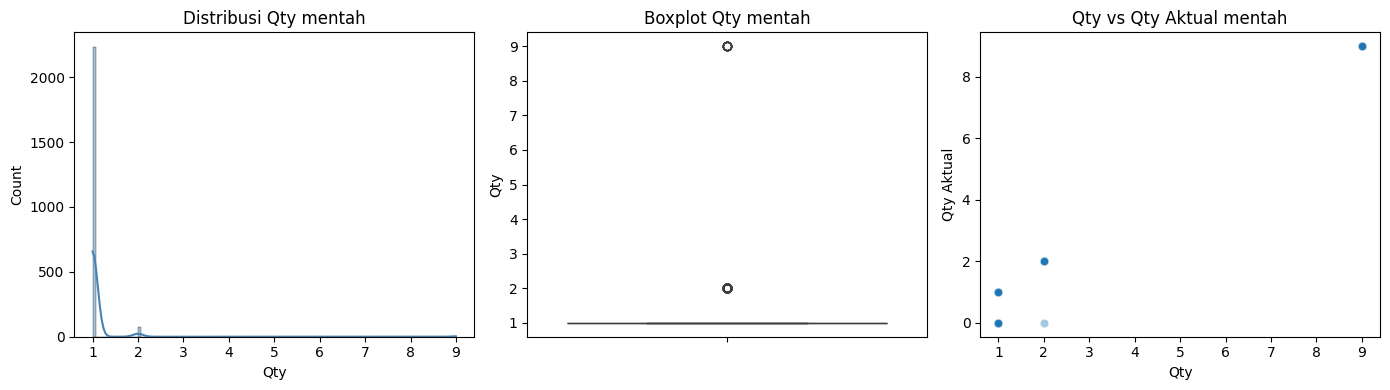

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig,ax=plt.subplots(1,3,figsize=(14,4))
sns.histplot(q_awal,kde=q_awal.nunique()>1,ax=ax[0],color='steelblue'); ax[0].set_title('Distribusi Qty mentah')
sns.boxplot(y=q_awal,ax=ax[1]); ax[1].set_title('Boxplot Qty mentah')
sns.scatterplot(data=angka_awal,x='Qty',y='Qty Aktual',ax=ax[2],alpha=.4); ax[2].set_title('Qty vs Qty Aktual mentah')
plt.tight_layout(); plt.show()

## **BAB 3 (Memuat & Memeriksa)**


---



---



### 3.1 Import library dan loading dataset


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Memuat kembali CSV mentah secara eksplisit untuk inspeksi.
df_raw = pd.read_csv(CSV,dtype=str,encoding='utf-8-sig')
df_audit = df_raw.apply(lambda c:c.str.strip().replace('',np.nan))
print('Dataset:',CSV)

Dataset: rekap_ndr_lengkap.csv


### 3.2 Inspeksi dimensi dan struktur data


In [ ]:
print('Dimensi:',df_raw.shape)
print('Kolom:',df_raw.columns.tolist())
display(df_raw.drop(columns=['Nomor Resi'],errors='ignore').head(10))

Dimensi: (2324, 9)
Kolom: ['No', 'Tanggal', 'Platform', 'Nomor Resi', 'Jenis Knalpot', 'Tipe Motor', 'Qty', 'Qty Aktual', 'Keterangan']


,No,Tanggal,Platform,Jenis Knalpot,Tipe Motor,Qty,Qty Aktual,Keterangan
0,1,NaN,TikTok,Shijiro,GF,1,1,Selesai
1,2,NaN,TikTok,Shijiro,FAZZIO,1,1,Selesai
2,3,NaN,TikTok,Shijiro,M3,1,1,Selesai
3,4,NaN,TikTok,Shijiro,STYLO,1,1,Selesai
4,5,NaN,TikTok,Shijiro,M GT 115,1,1,Selesai
5,6,1/7/2026,TikTok,Shijiro,BN,1,1,Selesai
6,7,1/7/2026,TikTok,Shijiro,PCX 150,1,1,Selesai
7,8,1/7/2026,TikTok,Shijiro,SN,1,1,Selesai
8,9,1/7/2026,TikTok,Shijiro,GF,1,1,Selesai
9,10,1/7/2026,TikTok,Shijiro,NEX 2,1,1,Selesai


### 3.3 Pemeriksaan tipe data dan informasi umum


In [ ]:
df_raw.info()
inspeksi_tipe=df_audit.copy()
inspeksi_tipe['Tanggal']=pd.to_datetime(inspeksi_tipe['Tanggal'],format='mixed',dayfirst=True,errors='coerce')
for c in ['Qty','Qty Aktual']:
    inspeksi_tipe[c]=pd.to_numeric(inspeksi_tipe[c],errors='coerce')
for c in ['Platform','Keterangan','Jenis Knalpot','Tipe Motor']:
    inspeksi_tipe[c]=inspeksi_tipe[c].astype('category')
print('Tipe data untuk analisis pada salinan:')
inspeksi_tipe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2324 entries, 0 to 2323
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   No             2324 non-null   object
 1   Tanggal        2260 non-null   object
 2   Platform       1642 non-null   object
 3   Nomor Resi     2132 non-null   object
 4   Jenis Knalpot  2155 non-null   object
 5   Tipe Motor     2297 non-null   object
 6   Qty            2321 non-null   object
 7   Qty Aktual     2321 non-null   object
 8   Keterangan     2324 non-null   object
dtypes: object(9)
memory usage: 163.5+ KB
Tipe data untuk analisis pada salinan:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2324 entries, 0 to 2323
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   No             2324 non-null   object        
 1   Tanggal        2260 non-null   datetime64[ns]
 2   Platform       1642 non-n

### 3.4 Ringkasan statistik awal

In [ ]:
display(angka_awal.describe().T.round(2))
display(df_audit[['Platform','Jenis Knalpot','Tipe Motor','Keterangan']].describe().T)

,count,mean,std,min,25%,50%,75%,max
Qty,2321.0,1.06,0.53,1.0,1.0,1.0,1.0,9.0
Qty Aktual,2321.0,1.00,0.59,0.0,1.0,1.0,1.0,9.0


,count,unique,top,freq
Platform,1642,4,Shopee,835
Jenis Knalpot,2155,14,Shijiro,1790
Tipe Motor,2297,234,BN,113
Keterangan,2324,2,Selesai,2171


## **BAB 4 (Penanganan Data yang Hilang)**


---



---



### 4.1 Identifikasi dan visualisasi missing values


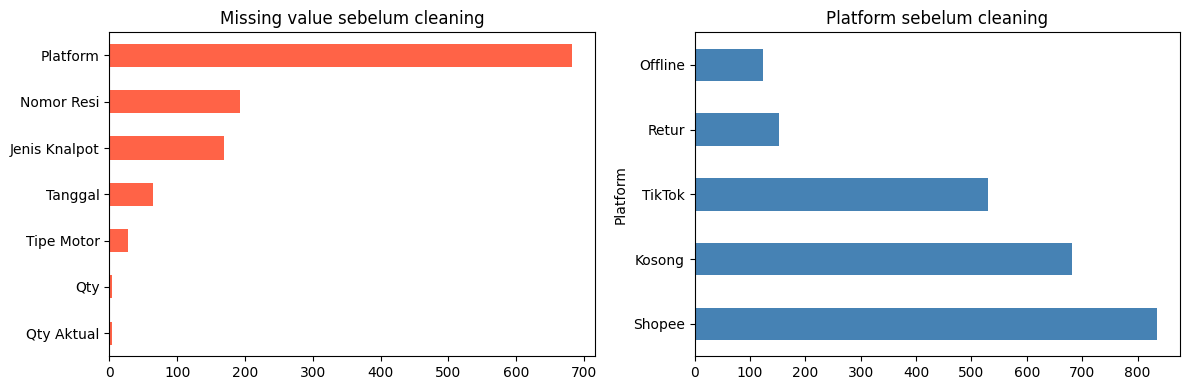

In [ ]:
#3.2 Visualisasi kualitas data-Grafik jumlah missing dan frekuensi platform sebelum perbaikan.
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,2,figsize=(12,4))
m=df_audit.isna().sum(); m[m>0].sort_values().plot.barh(ax=ax[0],color='tomato')
ax[0].set_title('Missing value sebelum cleaning')
p=df_audit['Platform'].fillna('Kosong').value_counts(); p.plot.barh(ax=ax[1],color='steelblue')
ax[1].set_title('Platform sebelum cleaning'); plt.tight_layout(); plt.show()

,Jumlah kosong,Persentase (%)
No,0,0.00
Tanggal,64,2.75
Platform,682,29.35
Nomor Resi,192,8.26
Jenis Knalpot,169,7.27
Tipe Motor,27,1.16
Qty,3,0.13
Qty Aktual,3,0.13
Keterangan,0,0.00


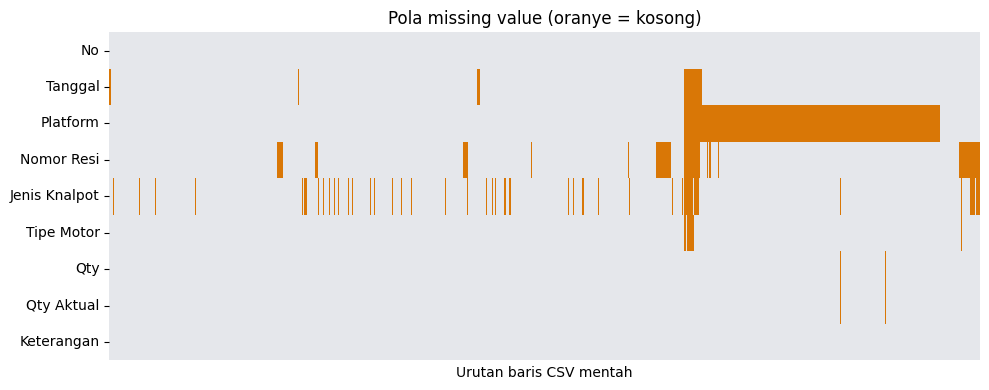

In [ ]:
display(pd.DataFrame({'Jumlah kosong':df_audit.isna().sum(),'Persentase (%)':100*df_audit.isna().mean()}).round(2))
fig,ax=plt.subplots(figsize=(10,4))
sns.heatmap(df_audit.isna().T.astype(int),cmap=['#e5e7eb','#d97706'],cbar=False,yticklabels=True,xticklabels=False,ax=ax)
ax.set_title('Pola missing value (oranye = kosong)'); ax.set_xlabel('Urutan baris CSV mentah');plt.tight_layout();plt.show()

### 4.2 Analisis mekanisme missing data

In [ ]:
# Bukti deskriptif: missing menurut label platform mentah (bukan uji mekanisme kausal).
missing_kanal=df_audit.isna().assign(Kanal=df_audit['Platform'].fillna('Tidak tercatat'))
display((missing_kanal.groupby('Kanal').mean()*100).round(2))

,No,Tanggal,Platform,Nomor Resi,Jenis Knalpot,Tipe Motor,Qty,Qty Aktual,Keterangan
Kanal,,,,,,,,,
Offline,0.0,0.00,0.0,100.00,21.77,2.42,0.00,0.00,0.0
Retur,0.0,0.00,0.0,1.31,3.92,0.65,0.00,0.00,0.0
Shopee,0.0,0.00,0.0,0.72,5.75,0.00,0.00,0.00,0.0
Tidak tercatat,0.0,6.89,100.0,7.92,5.57,3.37,0.44,0.44,0.0
TikTok,0.0,3.21,0.0,1.13,9.43,0.00,0.00,0.00,0.0


### 4.3 Strategi eliminasi (deletions)

Tidak digunakan dropna secara menyeluruh karena kehilangan atribut tidak selalu berarti transaksi tidak sah. Baris sumber nontransaksi tidak dimasukkan pada ekstraksi koordinat. Salinan lintas Shopee–TikTok pada resi dan status yang sama dikeluarkan hanya jika kanal yang benar menurut pola resi ditemukan, seluruh baris pada kanal benar dipertahankan. Pembelian dan Return tidak saling dihapus. Dampak pengeluaran dihitung dan disimpan pada log di bagian implementasi. Data mentah tetap utuh.

### 4.4 Strategi imputasi

Pemulihan langsung dari sumber PDF dan kamus, bukan imputasi mean, median, modus, KNN, atau MICE yang berisiko mengubah kuantitas dan atribut nyata. Qty diisi 1 hanya ketika tidak dicatat pada transaksi yang teridentifikasi, dengan penanda metode. Angka eksplisit yang gagal dibaca tetap verifikasi. Seri dan moncong menggunakan STANDAR/DEFAULT berdasarkan ketentuan bisnis, TIDAK BERLAKU digunakan untuk atribut yang memang tidak relevan. TIDAK DIKETAHUI digunakan bila informasi tidak dapat dipulihkan. Strategi ini tidak mengklaim nilai yang diimputasi sama dengan kenyataan.

### 4.5 Implementasi pemulihan, standardisasi, dan data cleaning

#### 4.5.1 Keputusan pengolahan hasil screening
- CSV asli tetap utuh, PDF menjadi sumber pemulihan atribut, Qty dan tanggal. Tanggal dipulihkan menurut posisi baris/sel gabungan dalam laporan, bukan diisi sembarang.
- SPX/SPXID, SHPE, S06 = Shopee; 57, 520, JX, JY, JT, ID = TikTok; 201 dan XA0 = WhatsApp; Offline atau tanpa resi = WhatsApp. S57 dikoreksi dengan menghapus S.
- Resi sama di Shopee dan TikTok pada status transaksi yang sama: mempertahankan semua baris pada platform sesuai pola resi dan keluarkan salinan pada platform salah. Resi berulang satu kanal dipertahankan, pembelian dan Return tidak saling dianggap duplikat. Keputusan dicatat.
- Hasil kroscek langsung pdf yg ekstrasinya tidak terbaca : (1)S062534839219: Shopee, Shijiro Sarfull, buang salinan TikTok. (2)S06588398628A: pembelian dan Return Shijiro Sarfull, (3)S06209879373A: pembelian dan Return Shijiro Sarteng.
- Seri tanpa keterangan = STANDAR. VORTEX dan VERTEX berbeda, VETEX = VERTEX, MET = METALICA. SUNBLUE hanya warna. T SS = TAMENG SS.
- Moncong tanpa catatan = DEFAULT. SHI = SHIJIRO; KENOCHI/KINOCI = KINOCHI; B3 = BAUT 3, bukan motor. Shijiro/Kinochi hanya berlaku untuk METALICA. Jika PDF secara eksplisit mencantumkan moncong tersebut pada seri lain, nilai sumber disimpan, menggunakan kolom tersendiri untuk nilai menurut aturan bisnis, dan memberi tanda konflik untuk verifikasi. Tidak menghapus bukti.
- Sarangan tanpa keterangan = DEFAULT. Aksesori menggunakan TIDAK BERLAKU pada atribut yang tidak relevan.
- Kamus motor dan konfirmasi tambahan: BEAT FI tipe tersendiri; NB = BEAT NEW; SS NEW VARIO = VARIO 125 NEW; SS MIO = MIO M3. Jika tidak dapat dipulihkan, TIDAK DIKETAHUI, bukan modus.
- Qty angka utuh dari PDF. Jika Qty tidak dicatat pada transaksi valid, imputasi 1 dengan penanda; angka eksplisit gagal terbaca wajib diperiksa. Bracket paket tidak menambah unit; aksesori terjual terpisah dihitung sesuai Qty.
- Status SELESAI dan RETURN. Return dikurangi pada tanggal pengembalian; tanpa resi = WhatsApp. Return dari periode sebelumnya tetap sah. Nilai net negatif/outlier valid tidak dihapus.
- PDF dilaporkan mencakup seluruh periode. Minggu tidak beroperasi rutin tetapi pesanan dapat masuk. Kalender lengkap 123 hari diaktifkan hanya setelah kelengkapan ekstraksi terbukti; hari tanpa catatan yang belum terverifikasi bukan otomatis nol.
- Target total Qty Aktual harian seluruh produk; train Juli–September, test Oktober; MAE utama, RMSE tambahan. Transformasi dan ambang outlier dipelajari dari train. Lag menggunakan informasi masa lalu, bukan target saat ini.
- Produk yang hanya mencantumkan Shijiro, Kinochi, Non Baut, atau B3 tanpa keterangan tipe motor dan telah dikonfirmasi melalui screening diklasifikasikan sebagai aksesori moncong yang dijual secara terpisah.
- Tipe motor, seri, sarangan, dan pabrikan pada aksesori moncong diberikan kategori TIDAK BERLAKU.
- Jenis moncong dan jenis baut pada aksesori tetap dipertahankan.
- Penulisan SS NEW NMAX distandardisasi menjadi NMAX NEW dengan pabrikan Yamaha.
- Moncong ganda pada resi SPXID06545443404A dikoreksi menjadi KINOCHI berdasarkan konfirmasi hasil screening.
- Seluruh koreksi atribut dilakukan tanpa mengubah jumlah transaksi maupun Qty penjualan.

#### 4.5.2 Membaca ulang posisi kolom PDF


In [ ]:
%pip install -q pymupdf
import fitz, re, pandas as pd, numpy as np
from pathlib import Path

from pathlib import Path

PDFS = {
    'jul': Path('Online Juli.pdf'),
    'aug': Path('Online Agustus.pdf'),
    'sep': Path('Online September.pdf'),
    'oct': Path('Online Oktober.pdf')
}

# Memeriksa ketersediaan file PDF
for bulan, file in PDFS.items():
    assert file.exists(), f"File tidak ditemukan: {file}"

print("Seluruh file PDF tersedia.")

# x center profile per section: date, no, resi left/right, motor left/right, sh, ki, full, teng, qty, buyer span, bracket centers
PROFILES = {
 'jul_tiktok': (156,207,(221,350),(350,449),474,523,570,619,671,None,None),
 'jul_shopee': (149,202,(219,362),(362,461),486,535,584,635,688,None,None),
 'jul_wa': (29,71,None,(139,204),227,275,320,367,705,(87,139),(410,439)),
 'jul_return': (100,152,(170,322),(322,402),426,474,516,564,621,None,None),
 'aug_tiktok': (72,123,(138,260),(260,365),389,438,479,526,581,None,None),
 'aug_shopee': (65,119,(135,274),(274,365),389,439,488,535,585,None,None),
 'aug_wa': (29,71,None,(144,240),265,318,372,427,686,(88,144),(469,495)),
 'aug_return': (64,116,(133,284),(284,365),390,438,479,527,585,None,None),
 'sep_tiktok': (72,123,(138,260),(260,365),389,438,479,526,581,None,None),
 'sep_shopee': (65,119,(135,279),(279,377),402,450,491,540,597,None,None),
 'sep_wa': (64,105,None,(174,237),261,309,350,395,658,(122,174),(440,471)),
 'sep_return': (64,116,(133,284),(284,365),390,438,479,527,585,None,None),
 'oct_online': (107,171,(190,330),(400,540),564,612,663,715,None,None,None),
 'oct_return': (106,None,(165,329),(400,540),562,610,661,713,None,None,None),
 'oct_wa': (95,142,None,(207,275),299,347,388,442,757,(162,207),(497,545)),
}
SECTIONS = {'jul':[(1,9,'tiktok'),(10,20,'shopee'),(21,21,'wa'),(22,23,'return')], 'aug':[(1,8,'tiktok'),(9,18,'shopee'),(19,19,'wa'),(20,20,'return')], 'sep':[(1,7,'tiktok'),(8,19,'shopee'),(20,21,'wa'),(22,23,'return')], 'oct':[(15,33,'online'),(34,35,'return'),(36,37,'wa')]}
DATE_PATTERN=r'\d{1,2}[-/]\d{1,2}[-/]\d{2,4}'
PRIVATE = str.maketrans({'\uf030':'0','\uf031':'1','\uf032':'2','\uf020':' ','\uf050':'1'})
def text_clean(s): return re.sub(r'\s+',' ',str(s).translate(PRIVATE)).strip()
def extract_sources(paths):
 rows=[]
 for month,path in paths.items():
  with fitz.open(path) as doc:
   for first,last,kind in SECTIONS[month]:
    date_prev=''; buyer_prev=''
    date_x,no_x,resi_range,motor_range,sh,ki,full,teng,qty_x,buyer_range,bracket=PROFILES[month+'_'+kind]
    for page_no in range(first,last+1):
     page=doc[page_no-1]; words=[((a+c)/2,(b+d)/2,t) for a,b,c,d,t,*_ in page.get_text('words')]
     # batas horizontal pada sel tanggal (termasuk tanggal yang digabung)
     edges=sorted({round(d['rect'].y0,1) for d in page.get_drawings() if d['rect'].height<=1.5 and d['rect'].width>12 and d['rect'].x0+2<date_x<d['rect'].x1-2})
     dates=[(y,t) for x,y,t in words if abs(x-date_x)<30 and re.fullmatch(DATE_PATTERN,t)]
     spans=[]
     for y,t in dates:
      above=[a for a in edges if a<y-1]; below=[a for a in edges if a>y+1]; spans.append((max(above,default=y-8),min(below,default=y+8),t,y))
     # baris diidentifikasi dari nomor urut atau posisi resi; offline juga dari kolom Qty
     row_x = no_x if no_x is not None else 240
     row_edges=sorted({round(d['rect'].y0,1) for d in page.get_drawings() if d['rect'].height<=1.5 and d['rect'].width>12 and d['rect'].x0+2<row_x<d['rect'].x1-2})
     if no_x is None:
      anchors=[y for x,y,t in words if resi_range[0]<x<resi_range[1] and re.fullmatch(r'[A-Z0-9][A-Z0-9-]{5,}',t,re.I)]
     else:
      anchors=[y for x,y,t in words if abs(x-no_x)<12 and re.fullmatch(r'\d{1,3}',t)]
     if kind=='wa':
      # termasuk baris lanjutan pembeli yang tidak memiliki nomor urut
      anchors += [y for x,y,t in words if abs(x-qty_x)<24 and re.fullmatch(r'\d{1,3}',text_clean(t)) and any(motor_range[0]<xx<motor_range[1] and abs(yy-y)<4 and re.search('[A-Za-z]',tt) for xx,yy,tt in words)]
     anchors=sorted(anchors); ys=[]
     for y in anchors:
      if not ys or y-ys[-1]>4: ys.append(y)
     seen_bounds=set()
     for j,y in enumerate(ys):
      lo=max([a for a in row_edges if a<y-1],default=y-7); hi=min([a for a in row_edges if a>y+1],default=y+7)
      if hi-lo>60:lo,hi=y-7,y+7
      # Retur Oktober: beberapa garis tabel mencakup dua resi. Batasi dengan titik tengah antar anchor resi.
      if no_x is None:
       if j>0: lo=max(lo,(ys[j-1]+y)/2)
       if j+1<len(ys): hi=min(hi,(y+ys[j+1])/2)
      key=(lo,hi)
      if key in seen_bounds:continue
      seen_bounds.add(key)
      rw=sorted([(x,t) for x,yy,t in words if lo+0.4<=yy<hi-0.4],key=lambda a:a[0]);
      def zone(lo,hi):return ' '.join(t for x,t in rw if lo<=x<hi)
      def near(x,w=20):return zone(x-w,x+w)
      def flag(x):
       s=text_clean(near(x,19));return bool(re.search(r'[1-9✔✓VvΠ]',s))
      r=text_clean(zone(*resi_range)) if resi_range else ''
      motor=text_clean(zone(*motor_range))
      if resi_range and not re.fullmatch(r'[A-Z0-9][A-Z0-9-]{3,}',r,re.I):
       if not r and motor and re.search(r'[A-Za-z]',motor) and not re.search(r'TOTAL|MOTOR|BARANG|KNALPOT',motor,re.I):pass
       else:continue
      qtxt=text_clean(near(qty_x,24)) if qty_x else ''
      q=int(qtxt) if re.fullmatch(r'\d+',qtxt) else np.nan
      if kind=='wa' and not motor and pd.isna(q):continue
      if kind=='wa' and not motor:continue
      # Oktober online/retur: PDF tidak punya kolom Qty terpisah, gunakan aturan 1 per baris transaksi
      if qty_x is None:
       q=np.nan
      hits=[(a,b,t,dy) for a,b,t,dy in spans if a-1<=y<=b+1]
      if hits: date_prev=min(hits,key=lambda a:abs(a[3]-y))[2]
      elif dates:
       older=[(dy,t) for dy,t in dates if dy<=y+4];
       if older: date_prev=older[-1][1]
      buyer=text_clean(zone(*buyer_range)) if buyer_range else ''
      if buyer:buyer_prev=buyer
      mon=' / '.join([v for x,v in [(sh,'SHIJIRO'),(ki,'KINOCHI')] if flag(x)])
      sar=' / '.join([v for x,v in [(full,'SARFULL'),(teng,'SARTENG')] if flag(x)])
      rows.append({'Sumber PDF':Path(path).name,'Bulan Sumber':month,'Halaman':page_no,'Posisi Y':round(y,1),'No PDF':text_clean(near(no_x,12)) if no_x else '', 'Tanggal':date_prev,'Platform':{'wa':'WhatsApp','tiktok':'TikTok','shopee':'Shopee','online':'Online','return':'Retur'}[kind], 'Nomor Resi':r,'Tipe Motor':motor,'Kode Produk':text_clean(zone(330,400)) if month=='oct' and kind!='wa' else '', 'Moncong':mon,'Sarangan':sar,'Bracket': ' / '.join(str(j+1) for j,x in enumerate(bracket or []) if flag(x)), 'Qty':q,'Qty Teks PDF':qtxt,'Qty Sumber':'Kolom Qty' if qty_x is not None else 'Tanpa kolom Qty', 'Keterangan':'Return' if kind=='return' else 'Selesai','Pembeli':buyer_prev if kind=='wa' else '', 'Teks Baris': ' | '.join(t for x,t in rw), 'Tanggal Metode':'Sel tanggal PDF' if hits else 'Lanjutan tanggal'})
 return pd.DataFrame(rows)


df_pdf = extract_sources(PDFS)
assert not df_pdf.empty, "Ekstraksi kosong; periksa nama/layout PDF"
df_pdf.insert(0,"ID Baris", [f"PDF-{i:05d}" for i in range(1,len(df_pdf)+1)])
print("Baris kandidat PDF:",len(df_pdf))
display(df_pdf.groupby(["Bulan Sumber","Platform"]).agg(Baris=("ID Baris","size"),Qty_Terbaca=("Qty","sum")))
display(df_pdf.head())
df_pdf.to_csv("rekap_ndr_pemulihan_pdf.csv",index=False,encoding="utf-8-sig")

Seluruh file PDF tersedia.
Baris kandidat PDF: 2260


Baris  Qty_Terbaca
Bulan Sumber Platform                    
aug          Retur        23         23.0
             Shopee      245        245.0
             TikTok      196        196.0
             WhatsApp     11        105.0
jul          Retur        40         40.0
             Shopee      255        255.0
             TikTok      189        189.0
             WhatsApp     11         57.0
oct          Online      638          0.0
             Retur        52          0.0
             WhatsApp     53        162.0
sep          Retur        36         36.0
             Shopee      330        330.0
             TikTok      144        144.0
             WhatsApp     37        152.0

,ID Baris,Sumber PDF,Bulan Sumber,Halaman,Posisi Y,No PDF,Tanggal,Platform,Nomor Resi,Tipe Motor,...,Moncong,Sarangan,Bracket,Qty,Qty Teks PDF,Qty Sumber,Keterangan,Pembeli,Teks Baris,Tanggal Metode
0,PDF-00001,Online Juli.pdf,jul,1,134.9,1,1/7/2026,TikTok,JX9837457654,GF,...,SHIJIRO,SARTENG,,1.0,1,Kolom Qty,Selesai,,1 | JX9837457654 | GF |  |  | 1 | 1,Sel tanggal PDF
1,PDF-00002,Online Juli.pdf,jul,1,150.6,2,1/7/2026,TikTok,570489471876,FAZZIO,...,SHIJIRO,SARFULL,,1.0,1,Kolom Qty,Selesai,,2 | 570489471876 | FAZZIO |  |  | 1,Sel tanggal PDF
2,PDF-00003,Online Juli.pdf,jul,1,166.2,3,1/7/2026,TikTok,570489482696,M3,...,SHIJIRO,SARTENG,,1.0,1,Kolom Qty,Selesai,,3 | 570489482696 | M3 |  |  | 1 | 1,Sel tanggal PDF
3,PDF-00004,Online Juli.pdf,jul,1,181.4,4,1/7/2026,TikTok,JX9837758573,STYLO,...,SHIJIRO,SARFULL,,1.0,1,Kolom Qty,Selesai,,4 | JX9837758573 | STYLO |  |  | 1,Sel tanggal PDF
4,PDF-00005,Online Juli.pdf,jul,1,197.1,5,1/7/2026,TikTok,JX9834598373,M GT 115,...,SHIJIRO,SARTENG,,1.0,1,Kolom Qty,Selesai,,5 | JX9834598373 | M | GT | 115 |  |  | 1 | 1,Sel tanggal PDF


#### 4.5.3 Rekonsiliasi CSV hasil BAB 1 dengan kandidat PDF


In [ ]:
def kunci_resi(s):
    return s.fillna('').astype(str).str.strip().str.upper().replace({'-':'','NAN':''})
def ringkas_kunci(d):
    temp=pd.DataFrame({'Resi':kunci_resi(d['Nomor Resi']),
        'Status':d['Keterangan'].fillna('').str.upper().replace('RETUR','RETURN')})
    return temp.groupby(['Resi','Status']).size()
rekon=pd.concat([ringkas_kunci(df_raw).rename('CSV Lama'),ringkas_kunci(df_pdf).rename('PDF Kandidat')],axis=1).fillna(0).astype(int)
rekon['Selisih']=rekon['PDF Kandidat']-rekon['CSV Lama']
selisih=rekon[rekon['Selisih']!=0].reset_index()
print('Jumlah kelompok berbeda:',len(selisih))
display(selisih)
selisih.to_csv('audit_selisih_csv_pdf.csv',index=False,encoding='utf-8-sig')
# Mulai dari baris sumber, bukan menggabungkan buta sehingga Return tidak terduplikasi.
df=df_pdf.copy()
df['Nomor Resi']=kunci_resi(df['Nomor Resi'])
df['Keterangan']=df['Keterangan'].str.upper().replace('RETUR','RETURN')
for c in ['Tanggal','Platform','Tipe Motor','Kode Produk','Moncong','Sarangan','Qty','Bracket']:
    df[c+' Asli']=df[c]
log=[]; belum=[]
def ubah(mask,col,val,alasan):
    for i in df.index[mask]:
        old=df.at[i,col]
        if str(old)!=str(val):
            log.append({'ID Baris':df.at[i,'ID Baris'],'Kolom':col,'Sebelum':old,'Sesudah':val,'Alasan':alasan})
            df.at[i,col]=val

def manual(resi, fields, status=None, tanggal=None, pilih_sar=None, alasan='Screening PDF pengguna'):
    mask=df['Nomor Resi'].eq(resi)
    if status: mask &= df['Keterangan'].eq(status)
    if tanggal: mask &= df['Tanggal_dt'].eq(pd.Timestamp(tanggal))
    if pilih_sar: mask &= df['Sarangan'].eq(pilih_sar)
    if mask.sum()!=1:
        belum.append({'Nomor Resi':resi,'Status':status,'Tanggal':tanggal,'Jumlah Kandidat':int(mask.sum()),'Koreksi':str(fields)})
        return
    for c,v in fields.items(): ubah(mask,c,v,alasan)
print('Selisih jumlah baris awal:', len(df_raw)-len(df_pdf))
print('Kandidat PDF > CSV per kelompok:', selisih['Selisih'].clip(lower=0).sum())
print('CSV > kandidat PDF per kelompok:', (-selisih['Selisih']).clip(lower=0).sum())

Jumlah kelompok berbeda: 7


,Resi,Status,CSV Lama,PDF Kandidat,Selisih
0,,RETURN,2,0,-2
1,,SELESAI,190,123,-67
2,XA02D01X,SELESAI,0,1,1
3,XA02E04C7,SELESAI,0,1,1
4,XA02E05X,SELESAI,0,1,1
5,XA04B02,SELESAI,0,1,1
6,XA07X,SELESAI,0,1,1


Selisih jumlah baris awal: 64
Kandidat PDF > CSV per kelompok: 5
CSV > kandidat PDF per kelompok: 69


#### 4.5.4 Pemulihan tanggal dan koreksi manual


In [ ]:
ubah(df['Tanggal'].eq('15/01/2026') | df['Tanggal'].eq('15/1/2026'),'Tanggal','15/10/2026','Koreksi typo admin')
df['Tanggal_dt']=pd.to_datetime(df['Tanggal'],dayfirst=True,format='mixed',errors='coerce')
for r,t,s in [('570489482696','20/08/2026','RETURN'),('JX9837457654','28/07/2026','RETURN'),
              ('570489471876','01/07/2026','SELESAI'),('JX9837758573','01/07/2026','SELESAI'),('JX9834598373','01/07/2026','SELESAI')]:
    manual(r,{'Tanggal':t},status=s)
df['Tanggal_dt']=pd.to_datetime(df['Tanggal'],dayfirst=True,format='mixed',errors='coerce')
df['Bulan']=df['Tanggal_dt'].dt.strftime('%Y-%m')
masalah_tgl=~df['Tanggal_dt'].between('2026-07-01','2026-10-31')
print('Tanggal belum valid:',masalah_tgl.sum())
display(df.loc[masalah_tgl,['ID Baris','Sumber PDF','Halaman','Tanggal','Nomor Resi']])

Tanggal belum valid: 0


,ID Baris,Sumber PDF,Halaman,Tanggal,Nomor Resi


#### 4.5.5 Standardisasi platform dan resi


In [ ]:
def normal_resi(r):
    if pd.isna(r): return ''
    r=str(r).strip().upper()
    if r in ('','-','NAN','NONE','<NA>','TANPA RESI','TANPA_RESI'): return ''
    return r[1:] if r.startswith('S57') else r

def pola_kanal(r):
    r=normal_resi(r)
    if not r or r.startswith(('201','XA0')): return 'WhatsApp'
    if r.startswith(('SPX','SHPE','S06')): return 'Shopee'
    if r.startswith(('57','520','JX','JY','JT','ID')): return 'TikTok'
    return None

jumlah_awal_platform=len(df)
qty_awal_platform=df['Qty Asli'].copy()
df['Nomor Resi Asli']=df['Nomor Resi'].copy()
for r in df['Nomor Resi'].unique():
    if normal_resi(r)!=r: ubah(df['Nomor Resi'].eq(r),'Nomor Resi',normal_resi(r),'Normalisasi resi / koreksi S57')
kanal_asli=df['Platform Asli'].fillna('').str.strip().str.upper().map({'SHOPEE':'Shopee','TIKTOK':'TikTok','OFFLINE':'WhatsApp','WHATSAPP':'WhatsApp'})
df['Kanal Asli Normal']=kanal_asli
df['Platform_Pola']=df['Nomor Resi'].map(pola_kanal)
mask_resi=df['Nomor Resi'].ne('')
known=df.loc[mask_resi & kanal_asli.notna()]
lookup=known.groupby('Nomor Resi')['Kanal Asli Normal'].agg(lambda s: s.iloc[0] if s.nunique()==1 else None)
def resolve(row):
    r=row['Nomor Resi']; p=row['Platform_Pola']; a=row['Kanal Asli Normal']
    if not r: return 'WhatsApp','Tanpa resi'
    if pd.notna(p): return p,'Pola resi terkonfirmasi'
    if pd.notna(a): return a,'Kanal asli; prefiks belum dikenal'
    if r in lookup.index and pd.notna(lookup[r]): return lookup[r],'Kanal sumber konsisten; prefiks belum dikenal'
    return 'WhatsApp','Dugaan; prefiks belum dikenal'
resolved=df.apply(resolve,axis=1,result_type='expand')
for i,p in resolved[0].items():
    if df.at[i,'Platform']!=p:
        log.append({'ID Baris':df.at[i,'ID Baris'],'Kolom':'Platform','Sebelum':df.at[i,'Platform'],'Sesudah':p,'Alasan':resolved.at[i,1]})
df['Platform']=resolved[0];df['Metode Platform']=resolved[1]
df['Platform Diubah']=df['Platform Asli'].ne(df['Platform'])
df['Prefiks Belum Dikenal']=mask_resi & df['Platform_Pola'].isna()
df['Konflik Platform Asli']=df['Nomor Resi'].isin(known.groupby('Nomor Resi')['Kanal Asli Normal'].nunique().loc[lambda s:s>1].index)
assert len(df)==jumlah_awal_platform and df['Qty Asli'].equals(qty_awal_platform)
display(df['Platform'].value_counts());print('Prefiks belum dikenal:',df['Prefiks Belum Dikenal'].sum())

,count
Platform,
Shopee,1320
TikTok,680
WhatsApp,260


Prefiks belum dikenal: 0


#### 4.5.6 Visualisasi platform sebelum dan sesudah standardisasi


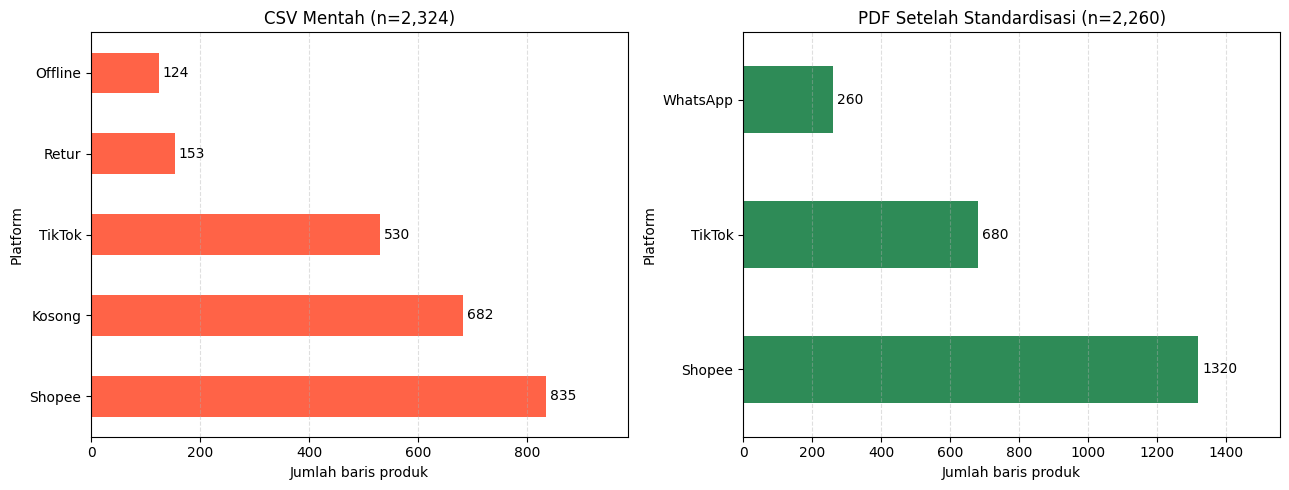

Transisi kanal pada baris PDF yang sama:


Platform,Shopee,TikTok,WhatsApp,All
Platform Asli,,,,
Online,476,88,74,638
Retur,74,77,0,151
Shopee,760,1,69,830
TikTok,10,514,5,529
WhatsApp,0,0,112,112
All,1320,680,260,2260


In [ ]:
import matplotlib.pyplot as plt
sebelum = df_audit['Platform'].fillna('Kosong').value_counts()
sesudah = df['Platform'].value_counts()
fig, ax = plt.subplots(1,2,figsize=(13,5))
for a, counts, title, color in [(ax[0],sebelum,'CSV Mentah','tomato'),(ax[1],sesudah,'PDF Setelah Standardisasi','seagreen')]:
    counts.plot.barh(ax=a,color=color)
    a.set_title(f'{title} (n={counts.sum():,})')
    a.set_xlabel('Jumlah baris produk')
    a.grid(axis='x',linestyle='--',alpha=.4)
    for bar in a.containers: a.bar_label(bar,padding=3)
    a.margins(x=.18)
plt.tight_layout(); plt.show()
print('Transisi kanal pada baris PDF yang sama:')
display(pd.crosstab(df['Platform Asli'].fillna('Kosong').replace('','Kosong'),df['Platform'],margins=True))

#### 4.5.7 Penanganan resi ganda lintas platform


In [ ]:
kunci=['Nomor Resi','Keterangan']
market=df['Kanal Asli Normal'].isin(['Shopee','TikTok']) & df['Nomor Resi'].ne('')
m=df.loc[market].copy()
m['Jumlah Kanal Sumber']=m.groupby(kunci)['Kanal Asli Normal'].transform('nunique')
m['Kanal Benar']=m['Kanal Asli Normal'].eq(m['Platform_Pola'])
m['Ada Kanal Benar']=m.groupby(kunci)['Kanal Benar'].transform('any')
lintas=m.loc[m['Jumlah Kanal Sumber'].gt(1)].copy()
lintas['Keputusan Duplikasi']=np.select([~lintas['Ada Kanal Benar'],lintas['Kanal Benar']],['PERLU REVIEW','PERTAHANKAN'],default='KELUARKAN SALINAN LINTAS PLATFORM')
keluarkan=lintas.loc[lintas['Keputusan Duplikasi'].eq('KELUARKAN SALINAN LINTAS PLATFORM')].copy()
pending_lintas=set(lintas.loc[lintas['Keputusan Duplikasi'].eq('PERLU REVIEW'),'Nomor Resi'])
for _,r in keluarkan.iterrows():
    log.append({'ID Baris':r['ID Baris'],'Kolom':'Baris transaksi','Sebelum':r['Platform Asli'],'Sesudah':'DIKELUARKAN','Alasan':'Resi/status sama di Shopee dan TikTok; pertahankan kanal sesuai pola resi'})
sebelum_duplikat=len(df)
df=df.drop(index=keluarkan.index).copy()
assert len(df)+len(keluarkan)==sebelum_duplikat
lintas.to_csv('audit_duplikasi_lintas_platform.csv',index=False,encoding='utf-8-sig')
keluarkan.to_csv('audit_baris_dikeluarkan.csv',index=False,encoding='utf-8-sig')
print('Resi lintas Shopee–TikTok:',lintas['Nomor Resi'].nunique())
print('Baris dikeluarkan:',len(keluarkan))
print('Baris dipertahankan:',len(df))
display(lintas[['ID Baris','Sumber PDF','Halaman','Tanggal','Nomor Resi','Keterangan','Platform Asli','Platform_Pola','Qty Asli','Keputusan Duplikasi']])
satu=df.loc[df['Nomor Resi'].ne('')].copy()
satu=satu.loc[satu.duplicated(['Nomor Resi','Platform','Keterangan'],keep=False)].copy()
satu.to_csv('audit_resi_berulang_dipertahankan.csv',index=False,encoding='utf-8-sig')
print('Baris resi berulang (kanal dan status sama) dipertahankan:',len(satu))

Resi lintas Shopee–TikTok: 10
Baris dikeluarkan: 10
Baris dipertahankan: 2250


,ID Baris,Sumber PDF,Halaman,Tanggal,Nomor Resi,Keterangan,Platform Asli,Platform_Pola,Qty Asli,Keputusan Duplikasi
1013,PDF-01014,Online September.pdf,2,9/9/2026,S064072130969,SELESAI,TikTok,Shopee,1.0,KELUARKAN SALINAN LINTAS PLATFORM
1014,PDF-01015,Online September.pdf,2,9/9/2026,S062309658189,SELESAI,TikTok,Shopee,1.0,KELUARKAN SALINAN LINTAS PLATFORM
1015,PDF-01016,Online September.pdf,2,9/9/2026,S066969723069,SELESAI,TikTok,Shopee,1.0,KELUARKAN SALINAN LINTAS PLATFORM
1016,PDF-01017,Online September.pdf,2,9/9/2026,S062849884549,SELESAI,TikTok,Shopee,1.0,KELUARKAN SALINAN LINTAS PLATFORM
1017,PDF-01018,Online September.pdf,3,9/9/2026,S064198894539,SELESAI,TikTok,Shopee,1.0,KELUARKAN SALINAN LINTAS PLATFORM
1018,PDF-01019,Online September.pdf,3,9/9/2026,S062534839219,SELESAI,TikTok,Shopee,1.0,KELUARKAN SALINAN LINTAS PLATFORM
1019,PDF-01020,Online September.pdf,3,9/9/2026,S064929549969,SELESAI,TikTok,Shopee,1.0,KELUARKAN SALINAN LINTAS PLATFORM
1020,PDF-01021,Online September.pdf,3,9/9/2026,S066608405909,SELESAI,TikTok,Shopee,1.0,KELUARKAN SALINAN LINTAS PLATFORM
1021,PDF-01022,Online September.pdf,3,9/9/2026,S065768819729,SELESAI,TikTok,Shopee,1.0,KELUARKAN SALINAN LINTAS PLATFORM
1022,PDF-01023,Online September.pdf,3,9/9/2026,S069954560449,SELESAI,TikTok,Shopee,1.0,KELUARKAN SALINAN LINTAS PLATFORM


Baris resi berulang (kanal dan status sama) dipertahankan: 58


#### 4.5.8 Validasi konflik platform


In [ ]:
mp=df.loc[df['Kanal Asli Normal'].isin(['Shopee','TikTok']) & df['Nomor Resi'].ne('')]
konflik_sisa=mp.groupby(kunci)['Kanal Asli Normal'].nunique().loc[lambda s:s>1]
resikonflik=df.loc[df['Nomor Resi'].ne('')].groupby('Nomor Resi')['Platform'].nunique().loc[lambda s:s>1]
df['Konflik Platform']=df['Nomor Resi'].isin(set(resikonflik.index)|pending_lintas|set(konflik_sisa.index.get_level_values(0)))
print('Konflik platform akhir:',len(resikonflik));print('Kelompok lintas platform asli tersisa:',len(konflik_sisa))
print('Prefiks belum dikenal:',df['Prefiks Belum Dikenal'].sum())
print('Platform kosong:',df['Platform'].isna().sum())

Konflik platform akhir: 0
Kelompok lintas platform asli tersisa: 0
Prefiks belum dikenal: 0
Platform kosong: 0


#### 4.5.9 Penerapan hasil screening

In [ ]:
ganda=df['Moncong'].str.contains('SHIJIRO',na=False)&df['Moncong'].str.contains('KINOCHI',na=False)
ubah(ganda&df['Tanggal_dt'].eq('2026-07-31'),'Moncong','SHIJIRO','Screening 31 Juli')
# Koreksi diseleksi menurut baris sumber, bukan menganggap seluruh daftar bertanggal 12 Oktober.
produk=[
('SPXID06991260842A','SHIJIRO','SARFULL','SELESAI','2026-10-12'),
('SPXID06972786667A','KINOCHI','SARFULL','SELESAI','2026-10-12'),
('570645064181','KINOCHI','SARFULL','SELESAI','2026-10-12'),
('SPXID06143438292A','SHIJIRO','SARFULL','SELESAI',None),
('SPXID06746823824A','SHIJIRO','SARTENG','SELESAI',None),
('SPXID06230013850A','SHIJIRO','SARFULL','SELESAI',None),
('JY2119279781','SHIJIRO','SARFULL','SELESAI',None),
('JY2180490422','SHIJIRO','SARFULL','SELESAI',None),
('S06247730096A','SHIJIRO','SARTENG','SELESAI',None),
('S06247730096A','SHIJIRO','SARFULL','RETURN',None),
('ID2346116610A','SHIJIRO','SARFULL','RETURN',None),

('JT80384120247','SHIJIRO','SARFULL','RETURN',None),

('S06210765547A','SHIJIRO','SARFULL','RETURN',None),
('JT11624649611','SHIJIRO','SARFULL','RETURN',None),
('S06035550264A','SHIJIRO','SARFULL','RETURN',None),
('S06383839392A','SHIJIRO','SARFULL','RETURN',None),
('570602866989','SHIJIRO','SARTENG','RETURN','2026-10-15'),

('SPXID06432212035A','SHIJIRO','SARFULL','SELESAI',None),
('SPXID06253166962A','SHIJIRO','SARFULL','SELESAI',None),
('JX9837758573','SHIJIRO','SARFULL','SELESAI','2026-07-01'),
('JX9834598373','SHIJIRO','SARTENG','SELESAI','2026-07-01'),
('S060134567309','SHIJIRO','SARTENG','RETURN','2026-10-06')]
for r,mon,sar,st,t in produk:
    manual(r,{'Moncong':mon,'Sarangan':sar},status=st,tanggal=t)
# Sarangan-only; tipe motor asli tetap tersedia sebagai jejak audit.
manual('SPXID06988493383A',{'Tipe Motor':'SARBOR','Moncong':'','Sarangan':'SARBOR'},status='SELESAI')
for r,t,m,st in [('570574770175','2026-09-24','GENIO','RETURN'),('570571359913','2026-09-24','BN','RETURN'),
 ('SPXID06991260842A','2026-10-12','GRAND FILLANO','SELESAI'),('S060134567309','2026-10-06','XEON RC/GT 125','RETURN'),
 ('S06769759798A','2026-10-29','SO','RETURN'),('S06293716166A','2026-10-29','MSP','RETURN'),('S061783406439','2026-10-29','M3','RETURN')]:
    manual(r,{'Tipe Motor':m},status=st,tanggal=t)
# Empat transaksi Ferry: cari di baris sumber, jangan menambahkan baris duplikat.
for motor,mon,q in [('SS SK','KINOCHI',None),('SS SN','KINOCHI',None),('SS GENIO','KINOCHI',2),('SS NN',None,None)]:
    mask=(df['Platform'].eq('WhatsApp')&df['Tanggal_dt'].eq('2026-10-28')&df['Pembeli'].str.upper().eq('FERRY')&df['Tipe Motor'].str.upper().eq(motor))
    if mask.sum()==1:
        ubah(mask,'Sarangan','SARFULL','Screening Ferry')
        ubah(mask,'Bracket','1','Screening Ferry')
        if mon: ubah(mask,'Moncong',mon,'Screening Ferry')
        # Qty tidak ditimpa oleh catatan manual. PDF halaman 37: SS GENIO = 1.
        if q is not None and pd.notna(df.loc[mask,'Qty Asli'].iloc[0]) and df.loc[mask,'Qty Asli'].iloc[0] != q:
            print('Perbedaan catatan screening dan Qty PDF:', motor, '| catatan:', q, '| PDF:', df.loc[mask,'Qty Asli'].iloc[0], '— gunakan PDF')
    else: belum.append({'Nomor Resi':'Tanpa resi','Tanggal':'2026-10-28','Koreksi':'Ferry '+motor,'Jumlah Kandidat':int(mask.sum())})
print('Jumlah koreksi nilai:',len(log))
display(pd.DataFrame(belum))
# Konfirmasi terbaru: terapkan kepada seluruh status yang relevan, bukan hanya satu baris.
for r,sar in [('S062534839219','SARFULL'),('S06588398628A','SARFULL'),('S06209879373A','SARTENG')]:
    mask=df['Nomor Resi'].eq(r)
    if mask.any():
        ubah(mask,'Moncong','SHIJIRO','Konfirmasi screening terakhir')
        ubah(mask,'Sarangan',sar,'Konfirmasi screening terakhir')
    else:
        belum.append({'Nomor Resi':r,'Status':None,'Tanggal':None,'Jumlah Kandidat':0,'Koreksi':'Konfirmasi terbaru belum ditemukan'})
print('Koreksi belum terpetakan:',len(belum))
display(pd.DataFrame(belum))

Perbedaan catatan screening dan Qty PDF: SS GENIO | catatan: 2 | PDF: 1.0 — gunakan PDF
Jumlah koreksi nilai: 902


""


Koreksi belum terpetakan: 0


""


#### 4.5.10 Pemisahan dan standardisasi atribut produk

In [ ]:
import unicodedata
import re
import pandas as pd
import numpy as np

def normal(s):
    if pd.isna(s): return ''
    return re.sub(r'\s+',' ',re.sub(r'[\uE000-\uF8FF]',' ',unicodedata.normalize('NFKC',str(s)))).strip().upper()

SERI=['VORTEX','VERTEX','METALICA','MOONLIGHT','LUSTER','KOU','SS']
WARNA=['SUNBLUE','BIRU','BLUE','GOLD','EMAS','HITAM','BLACK','SILVER','TITAN','MERAH','RED']
def klasifikasi(row):
    raw=normal(row['Tipe Motor']); kode=normal(row['Kode Produk'])
    raw=re.sub(r'\bVETEX\b','VERTEX',raw)
    # Seri dicari dalam nama dan kode; SUNBLUE bukan seri.
    seri=next((s for s in SERI if re.search(r'\b'+s+r'\b',raw)),None)
    if not seri and (re.search(r'\bMET\b',raw) or kode.startswith('MET')): seri='METALICA'
    if not seri and kode.startswith('SS'): seri='SS'
    if not seri:
        seri=next((s for s in SERI if s!='SS' and kode.startswith(s)),None)
    warna=next((w for w in WARNA if re.search(r'\b'+w+r'\b',raw)), 'TIDAK TERCATAT')
    if warna=='BLUE': warna='BIRU'
    if warna=='BLACK': warna='HITAM'
    if warna=='RED': warna='MERAH'
    mon0=normal(row['Moncong']).replace('KENOCHI','KINOCHI').replace('KINOCI','KINOCHI')
    sar0=normal(row['Sarangan'])
    # Aksesori eksplisit di nama produk, bukan tanda bracket paket.
    aks=(bool(re.match(r'^(?:TAMENG|TUTUP|BRACKET|BREKET|BAUT|SARFULL?|SARTENG|SARBOR|SARTUBOR|SARANGAN|T SS|T TITAN|T VORTEX)(?:\b|$)',raw)) and not re.search(r'\b(?:SHIJIRO|KINOCHI)\b',raw))
    aks=aks or raw=='T SS'
    if aks:
        sar=next((x for pat,x in [('SARTUBOR|TUBOR','TUBOR'),('SARBOR','SARBOR'),('SARFUL','SARFULL'),('SARTENG','SARTENG')] if re.search(pat,raw)),'TIDAK BERLAKU')
        return ['AKSESORI','TIDAK BERLAKU','TIDAK BERLAKU','TIDAK BERLAKU',sar,warna,'TAMENG SS' if raw=='T SS' else raw,False]
    if not any([raw,kode,mon0,sar0]):
        return ['TIDAK DIKETAHUI','TIDAK DIKETAHUI','TIDAK DIKETAHUI','TIDAK DIKETAHUI','TIDAK DIKETAHUI',warna,'TIDAK BERLAKU',False]
    seri=seri or 'STANDAR'
    # Ambil catatan eksplisit dari kolom moncong maupun nama barang.
    raw_mon=raw.replace('KENOCHI','KINOCHI').replace('KINOCI','KINOCHI')
    eksplisit=[]
    for pat,v in [(r'\b(?:SHIJIRO|SHI)\b','SHIJIRO'),(r'\bKINOCHI\b','KINOCHI'),(r'\b(?:B3|BAUT 3)\b','BAUT 3')]:
        if re.search(pat,mon0+' '+raw_mon): eksplisit.append(v)
    mon=' / '.join(eksplisit) or 'DEFAULT'
    # B3 berarti baut 3; jika Shijiro juga eksplisit, kedua atribut dicatat.
    jenis_mon=[m for m in eksplisit if m in ['SHIJIRO','KINOCHI']]
    konflik=bool(seri!='METALICA' and jenis_mon) or len(jenis_mon)>1
    mon_aturan=('BAUT 3' if 'BAUT 3' in eksplisit else 'DEFAULT') if seri!='METALICA' else mon
    sar=sar0 or next((x for pat,x in [('SARTUBOR|TUBOR','TUBOR'),('SARBOR','SARBOR'),('SARFUL','SARFULL'),('SARTENG','SARTENG')] if re.search(pat,raw)),'DEFAULT')
    if sar=='SARFUL': sar='SARFULL'
    return ['KNALPOT',seri,mon,mon_aturan,sar,warna,'TIDAK BERLAKU',konflik]

kolom_produk=['Kategori Produk','Seri','Moncong','Moncong Menurut Aturan','Sarangan','Warna','Aksesori','Konflik Atribut Seri']
df[kolom_produk]=pd.DataFrame(df.apply(klasifikasi,axis=1).tolist(),index=df.index,columns=kolom_produk)
df['Konflik Atribut Seri']=df['Konflik Atribut Seri'].astype(bool)
# Pisahkan tipe baut tanpa menghilangkan jenis moncong sumber.
df['Jenis Baut']=np.where(df['Moncong'].str.contains('BAUT 3',regex=False),'BAUT 3','TIDAK TERCATAT')
for c in ['Kategori Produk','Seri','Moncong','Moncong Menurut Aturan','Sarangan','Warna']:
    print(c);display(df[c].value_counts(dropna=False))
audit_atribut=df.loc[df['Konflik Atribut Seri'],['ID Baris','Sumber PDF','Halaman','Nomor Resi','Tipe Motor Asli','Kode Produk','Seri','Moncong Asli','Moncong','Moncong Menurut Aturan']].copy()
audit_atribut.to_csv('audit_konflik_atribut_seri.csv',index=False,encoding='utf-8-sig')
print('Konflik aturan seri vs bukti PDF:',len(audit_atribut))
display(audit_atribut.head(30))

Kategori Produk


,count
Kategori Produk,
KNALPOT,2180
AKSESORI,70


Seri


,count
Seri,
STANDAR,2042
TIDAK BERLAKU,70
METALICA,58
SS,45
VORTEX,19
KOU,5
VERTEX,4
MOONLIGHT,4
LUSTER,3


Moncong


,count
Moncong,
SHIJIRO,1945
KINOCHI,155
DEFAULT,78
TIDAK BERLAKU,70
SHIJIRO / BAUT 3,1
SHIJIRO / KINOCHI,1


... (4 outputs left out)

Warna


,count
Warna,
TIDAK TERCATAT,2236
TITAN,8
BIRU,4
SUNBLUE,2


Konflik aturan seri vs bukti PDF: 2086


,ID Baris,Sumber PDF,Halaman,Nomor Resi,Tipe Motor Asli,Kode Produk,Seri,Moncong Asli,Moncong,Moncong Menurut Aturan
0,PDF-00001,Online Juli.pdf,1,JX9837457654,GF,,STANDAR,SHIJIRO,SHIJIRO,DEFAULT
1,PDF-00002,Online Juli.pdf,1,570489471876,FAZZIO,,STANDAR,SHIJIRO,SHIJIRO,DEFAULT
2,PDF-00003,Online Juli.pdf,1,570489482696,M3,,STANDAR,SHIJIRO,SHIJIRO,DEFAULT
3,PDF-00004,Online Juli.pdf,1,JX9837758573,STYLO,,STANDAR,SHIJIRO,SHIJIRO,DEFAULT
4,PDF-00005,Online Juli.pdf,1,JX9834598373,M GT 115,,STANDAR,SHIJIRO,SHIJIRO,DEFAULT
5,PDF-00006,Online Juli.pdf,1,570488468384,BN,,STANDAR,SHIJIRO,SHIJIRO,DEFAULT
6,PDF-00007,Online Juli.pdf,1,570488414169,PCX 150,,STANDAR,SHIJIRO,SHIJIRO,DEFAULT
7,PDF-00008,Online Juli.pdf,1,JX9836167079,SN,,STANDAR,SHIJIRO,SHIJIRO,DEFAULT
8,PDF-00009,Online Juli.pdf,1,570489013282,GF,,STANDAR,SHIJIRO,SHIJIRO,DEFAULT
9,PDF-00010,Online Juli.pdf,1,JY1079200590,NEX 2,,STANDAR,SHIJIRO,SHIJIRO,DEFAULT


#### 4.5.11 Standardisasi tipe motor berdasarkan kamus dan hasil screening

In [ ]:
from pathlib import Path
import pandas as pd
import re

KAMUS = Path('Kamus singkatan motor.xlsx')
assert KAMUS.exists(), f"File tidak ditemukan: {KAMUS}"
kamus = pd.read_excel(KAMUS, sheet_name='Kamus Singkatan Motor', header=3, dtype=str)
kamus=kamus[kamus['Nama Motor Standar'].notna() & kamus['Pabrikan / Merk'].isin(['Honda','Yamaha','Suzuki'])]
def alias_key(s):return re.sub(r'[^A-Z0-9]','',normal(s))
alias={}
for _,r in kamus.iterrows():
    target=(r['Nama Motor Standar'],r['Pabrikan / Merk'])
    variasi=[r['Nama Motor Standar'],r['Format Standar di Tabel (Kolom F)']]+re.split(r'\s*/\s*',str(r['Singkatan Utama']))+str(r['Variasi Penulisan di Data Asli']).split(',')
    for v in variasi:
        k=alias_key(v)
        if k and k!='NAN': alias.setdefault(k,set()).add(target)
manual_motor={'NB':('BEAT NEW','Honda'),'BEATFI':('BEAT FI','Honda'),'SSNEWVARIO':('VARIO 125 NEW','Honda'),'SSMIO':('MIO M3','Yamaha'),'GT115':('MIO GT 115','Yamaha'),'150ADV':('ADV 150','Honda')}
for k,v in manual_motor.items():alias[k]={v}

def bersihkan_motor(s):
    s=normal(s)
    s=re.sub(r'\b(?:VORTEX|VERTEX|VETEX|METALICA|MET|MOONLIGHT|LUSTER|KOU|SS|SUNBLUE|BIRU|BLUE|GOLD|EMAS|HITAM|BLACK|SILVER|TITAN|MERAH|RED|SHIJIRO|SHI|KINOCHI|KENOCHI|KINOCI|SARFULL?|SARTENG|SARBOR|SARTUBOR|TUBOR|B3|BAUT 3|NON BAUT|BAUT|NON)\b',' ',s)
    return re.sub(r'\s+',' ',s).strip()

def motor_standar(row):
    if row['Kategori Produk']=='AKSESORI': return ['TIDAK BERLAKU','TIDAK BERLAKU','Aksesori','']
    raw=normal(row['Tipe Motor']); kode=normal(row['Kode Produk']); s=bersihkan_motor(raw)
    # Prioritas konfirmasi spesifik; tidak menganggap semua tulisan MIO adalah M3.
    if alias_key(raw) in manual_motor:
        name,maker=manual_motor[alias_key(raw)];return [name,maker,'Konfirmasi pengguna',s]
    candidates=set()
    for v in [s,kode,re.sub(r'^(?:METALICA|MET|VORTEX|VERTEX|VETEX|LUSTER|MOONLIGHT|KOU|SS|SUN)','',kode)]:
        if alias_key(v): candidates |= alias.get(alias_key(v),set())
    if len(candidates)==1:
        name,maker=next(iter(candidates));return [name,maker,'Kamus',s]
    return ['TIDAK DIKETAHUI','TIDAK DIKETAHUI','Ambigu' if len(candidates)>1 else 'Belum teridentifikasi',s]

df[['Tipe Motor Standar','Pabrikan','Metode Motor','Motor Teks Bersih']]=pd.DataFrame(df.apply(motor_standar,axis=1).tolist(),index=df.index)
motor_review=df.loc[df['Tipe Motor Standar'].eq('TIDAK DIKETAHUI'),['ID Baris','Sumber PDF','Halaman','Nomor Resi','Tipe Motor Asli','Tipe Motor','Kode Produk','Motor Teks Bersih','Metode Motor']].copy()
motor_review.to_csv('audit_motor_belum_diketahui.csv',index=False,encoding='utf-8-sig')
print('Motor tidak diketahui:',len(motor_review));display(motor_review)
display(df['Metode Motor'].value_counts())

Motor tidak diketahui: 16


,ID Baris,Sumber PDF,Halaman,Nomor Resi,Tipe Motor Asli,Tipe Motor,Kode Produk,Motor Teks Bersih,Metode Motor
41,PDF-00042,Online Juli.pdf,2,JY1077025505,SHIJIRO BAUT,SHIJIRO BAUT,,,Belum teridentifikasi
80,PDF-00081,Online Juli.pdf,4,JY1177891942,KINOCHI,KINOCHI,,,Belum teridentifikasi
354,PDF-00355,Online Juli.pdf,16,S060732638997,SHIJIRO,SHIJIRO,,,Belum teridentifikasi
375,PDF-00376,Online Juli.pdf,17,S064328542737,SHIJIRO NON BAUT,SHIJIRO NON BAUT,,,Belum teridentifikasi
423,PDF-00424,Online Juli.pdf,19,S066803399237,BAUT KINOCHI NON,BAUT KINOCHI NON,,,Belum teridentifikasi
452,PDF-00453,Online Juli.pdf,21,,SS NEW NMAX,SS NEW NMAX,,NEW NMAX,Belum teridentifikasi
463,PDF-00464,Online Juli.pdf,22,S065458904686,KINOCHI,KINOCHI,,,Belum teridentifikasi
743,PDF-00744,Online Agustus.pdf,11,S065132796408,KINOCHI,KINOCHI,,,Belum teridentifikasi
771,PDF-00772,Online Agustus.pdf,12,S066499478328,SHIJIRO,SHIJIRO,,,Belum teridentifikasi
1110,PDF-01111,Online September.pdf,7,JY1885875193,KINOCHI NON BAUT,KINOCHI NON BAUT,,,Belum teridentifikasi


,count
Metode Motor,
Kamus,2155
Aksesori,70
Belum teridentifikasi,16
Konfirmasi pengguna,9


#### 4.5.12 Finalisasi Atribut Produk dan Tipe Motor


In [ ]:
# 4.5.12 FINALISASI ATRIBUT PRODUK DAN TIPE MOTOR

import pandas as pd
import numpy as np

# Simpan kondisi sebelum koreksi
jumlah_awal = len(df)
qty_awal = df['Qty'].copy()

# ==========================================
# A. DAFTAR AKSESORI MONCONG TERKONFIRMASI
# ==========================================

aksesori_moncong = {
    'JY1077025505': 'SHIJIRO BAUT',
    'JY1177891942': 'KINOCHI',
    'S060732638997': 'SHIJIRO',
    'S064328542737': 'SHIJIRO NON BAUT',
    'S066803399237': 'BAUT KINOCHI NON',
    'S065458904686': 'KINOCHI',
    'S065132796408': 'KINOCHI',
    'S066499478328': 'SHIJIRO',
    'JY1885875193': 'KINOCHI NON BAUT',
    'S061397309579': 'SHIJIRO B3',
    'S062050279219': 'SHIJIRO',
    'S06955994666A': 'SHIJIRO NON BAUT',
    'JY1924239946': 'SHIJIRO NON BAUT',
    'SPXID06545443404A': 'KINOCHI NON BAUT',
    'JY2062421319': 'SHIJIRO NON BAUT'
}

# Identifikasi berdasarkan resi dan nama produk
resi_cek = (
    df['Nomor Resi']
    .fillna('')
    .str.strip()
    .str.upper()
)

produk_cek = df['Tipe Motor'].map(normal)

mask_aksesori = pd.Series(False, index=df.index)

# Memastikan setiap koreksi tepat sasaran
for resi, produk in aksesori_moncong.items():

    mask = (
        resi_cek.eq(resi) &
        produk_cek.eq(produk)
    )

    assert mask.sum() == 1, (
        f"Periksa kembali transaksi {resi}: "
        f"{mask.sum()} baris ditemukan"
    )

    mask_aksesori |= mask

# ==========================================
# B. KOREKSI KATEGORI PRODUK
# ==========================================

perbaikan = {
    'Kategori Produk': 'AKSESORI',
    'Seri': 'TIDAK BERLAKU',
    'Sarangan': 'TIDAK BERLAKU',
    'Tipe Motor Standar': 'TIDAK BERLAKU',
    'Pabrikan': 'TIDAK BERLAKU',
    'Metode Motor': 'Aksesori moncong terkonfirmasi',
    'Motor Teks Bersih': '',
    'Konflik Atribut Seri': False
}

for kolom, nilai in perbaikan.items():

    ubah(
        mask_aksesori,
        kolom,
        nilai,
        'Konfirmasi penjualan aksesori moncong'
    )

# ==========================================
# C. PERTAHANKAN JENIS MONCONG DAN BAUT
# ==========================================

for resi, produk in aksesori_moncong.items():

    mask = mask_aksesori & resi_cek.eq(resi)

    jenis_moncong = (
        'KINOCHI'
        if 'KINOCHI' in produk
        else 'SHIJIRO'
    )

    ubah(
        mask,
        'Moncong',
        jenis_moncong,
        'Jenis moncong aksesori terkonfirmasi'
    )

    ubah(
        mask,
        'Moncong Menurut Aturan',
        jenis_moncong,
        'Aksesori moncong dijual terpisah'
    )

    ubah(
        mask,
        'Aksesori',
        'MONCONG ' + produk,
        'Standardisasi nama aksesori'
    )

    # Standardisasi jenis baut
    if 'B3' in produk:
        jenis_baut = 'BAUT 3'

    elif 'NON' in produk.split() and 'BAUT' in produk.split():
        jenis_baut = 'NON BAUT'

    elif produk == 'SHIJIRO BAUT':
        jenis_baut = 'BAUT'

    else:
        jenis_baut = 'TIDAK TERCATAT'

    ubah(
        mask,
        'Jenis Baut',
        jenis_baut,
        'Pemisahan atribut baut'
    )

# ==========================================
# D. PEMULIHAN TIPE MOTOR NMAX
# ==========================================

mask_nmax = (
    produk_cek.eq('SS NEW NMAX') &
    df['Platform'].eq('WhatsApp') &
    df['Tanggal_dt'].eq(pd.Timestamp('2026-07-17'))
)

assert mask_nmax.sum() == 1, f"Periksa NMAX: {mask_nmax.sum()} baris ditemukan"

ubah(
    mask_nmax,
    'Tipe Motor Standar',
    'NMAX NEW',
    'Pemulihan tipe motor berdasarkan PDF'
)

ubah(
    mask_nmax,
    'Pabrikan',
    'Yamaha',
    'Standardisasi pabrikan motor'
)

ubah(
    mask_nmax,
    'Metode Motor',
    'Pemulihan teks PDF',
    'Hasil crosscheck tipe motor'
)

ubah(
    mask_nmax,
    'Motor Teks Bersih',
    'NEW NMAX',
    'Pemisahan seri dan tipe motor'
)

# ==========================================
# E. VALIDASI KEAMANAN DATA
# ==========================================

assert len(df) == jumlah_awal, (
    "Jumlah baris berubah!"
)

assert df['Qty'].equals(qty_awal), (
    "Qty mengalami perubahan!"
)

# ==========================================
# F. PEMERIKSAAN ULANG HASIL KOREKSI
# ==========================================

mon_ganda = (
    df['Moncong'].str.contains('SHIJIRO', na=False) &
    df['Moncong'].str.contains('KINOCHI', na=False)
)

motor_review = df.loc[
    df['Tipe Motor Standar'].eq('TIDAK DIKETAHUI'),
    [
        'ID Baris',
        'Sumber PDF',
        'Halaman',
        'Nomor Resi',
        'Tipe Motor Asli',
        'Tipe Motor',
        'Kode Produk',
        'Motor Teks Bersih',
        'Metode Motor'
    ]
].copy()

print("=== HASIL FINALISASI ATRIBUT PRODUK ===")

print("Aksesori moncong dikoreksi:",
      mask_aksesori.sum())

print("Motor NMAX berhasil dipulihkan:",
      mask_nmax.sum())

print("Sisa tipe motor tidak diketahui:",
      len(motor_review))

print("Sisa moncong ganda:",
      mon_ganda.sum())

print("Jumlah baris:", len(df))

print("Jumlah baris dan Qty tidak berubah.")

# Tampilkan hasil koreksi
display(
    df.loc[mask_aksesori | mask_nmax, [
        'Tanggal',
        'Nomor Resi',
        'Tipe Motor',
        'Kategori Produk',
        'Seri',
        'Moncong',
        'Jenis Baut',
        'Aksesori',
        'Tipe Motor Standar',
        'Qty'
    ]]
)

# ==========================================
# G. PEMBARUAN FILE AUDIT
# ==========================================

motor_review.to_csv(
    'audit_motor_belum_diketahui.csv',
    index=False,
    encoding='utf-8-sig'
)

audit_atribut = df.loc[
    df['Konflik Atribut Seri'],
    [
        'ID Baris',
        'Sumber PDF',
        'Halaman',
        'Nomor Resi',
        'Tipe Motor Asli',
        'Kode Produk',
        'Seri',
        'Moncong Asli',
        'Moncong',
        'Moncong Menurut Aturan'
    ]
].copy()

audit_atribut.to_csv(
    'audit_konflik_atribut_seri.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nFinalisasi atribut selesai.")

=== HASIL FINALISASI ATRIBUT PRODUK ===
Aksesori moncong dikoreksi: 15
Motor NMAX berhasil dipulihkan: 1
Sisa tipe motor tidak diketahui: 0
Sisa moncong ganda: 0
Jumlah baris: 2250
Jumlah baris dan Qty tidak berubah.


,Tanggal,Nomor Resi,Tipe Motor,Kategori Produk,Seri,Moncong,Jenis Baut,Aksesori,Tipe Motor Standar,Qty
41,7/7/2026,JY1077025505,SHIJIRO BAUT,AKSESORI,TIDAK BERLAKU,SHIJIRO,BAUT,MONCONG SHIJIRO BAUT,TIDAK BERLAKU,1.0
80,14/7/2026,JY1177891942,KINOCHI,AKSESORI,TIDAK BERLAKU,KINOCHI,TIDAK TERCATAT,MONCONG KINOCHI,TIDAK BERLAKU,1.0
354,22/7/2026,S060732638997,SHIJIRO,AKSESORI,TIDAK BERLAKU,SHIJIRO,TIDAK TERCATAT,MONCONG SHIJIRO,TIDAK BERLAKU,1.0
375,25/7/2026,S064328542737,SHIJIRO NON BAUT,AKSESORI,TIDAK BERLAKU,SHIJIRO,NON BAUT,MONCONG SHIJIRO NON BAUT,TIDAK BERLAKU,1.0
423,30/7/2026,S066803399237,BAUT KINOCHI NON,AKSESORI,TIDAK BERLAKU,KINOCHI,NON BAUT,MONCONG BAUT KINOCHI NON,TIDAK BERLAKU,1.0
452,17/7/2026,,SS NEW NMAX,KNALPOT,SS,SHIJIRO,TIDAK TERCATAT,TIDAK BERLAKU,NMAX NEW,10.0
463,8/7/2026,S065458904686,KINOCHI,AKSESORI,TIDAK BERLAKU,KINOCHI,TIDAK TERCATAT,MONCONG KINOCHI,TIDAK BERLAKU,1.0
743,8/8/2026,S065132796408,KINOCHI,AKSESORI,TIDAK BERLAKU,KINOCHI,TIDAK TERCATAT,MONCONG KINOCHI,TIDAK BERLAKU,1.0
771,11/8/2026,S066499478328,SHIJIRO,AKSESORI,TIDAK BERLAKU,SHIJIRO,TIDAK TERCATAT,MONCONG SHIJIRO,TIDAK BERLAKU,1.0
1110,30/9/2026,JY1885875193,KINOCHI NON BAUT,AKSESORI,TIDAK BERLAKU,KINOCHI,NON BAUT,MONCONG KINOCHI NON BAUT,TIDAK BERLAKU,1.0



Finalisasi atribut selesai.


#### 4.5.13 Validasi Qty dan perlakuan Return

In [ ]:
# Sumber utama Qty: hasil pembacaan kolom PDF di BAB 4.1.
q = pd.to_numeric(df['Qty Asli'], errors='coerce')
raw = df['Qty Teks PDF'].fillna('').astype(str).str.strip()
ada_kolom = df['Qty Sumber'].eq('Kolom Qty')
valid = ada_kolom & q.notna() & (q > 0) & (q % 1 == 0)
transaksi_valid = (
    df['Nomor Resi'].fillna('').str.strip().ne('') |
    df['Tipe Motor'].map(normal).ne('')
)
# Isi 1 hanya jika Qty tidak dicatat, bukan jika angka eksplisit gagal dibaca.
imputasi_kosong = ada_kolom & raw.eq('') & q.isna() & transaksi_valid
imputasi_tanpa_kolom = ~ada_kolom & q.isna() & transaksi_valid
mask_imputasi = imputasi_kosong | imputasi_tanpa_kolom

df['Qty'] = q.where(valid)
df.loc[mask_imputasi, 'Qty'] = 1
df['Qty Metode'] = np.select(
    [valid, imputasi_kosong, imputasi_tanpa_kolom],
    ['Angka eksplisit PDF', 'Imputasi 1: sel Qty kosong',
     'Imputasi 1: tanpa kolom Qty'],
    default='Perlu verifikasi Qty'
)
# Pastikan angka eksplisit tidak berubah setelah cleaning.
assert df.loc[valid, 'Qty'].eq(q.loc[valid]).all()

beli = df['Keterangan'].eq('SELESAI')
retur = df['Keterangan'].eq('RETURN')
df['Qty Pembelian'] = df['Qty'].where(beli, 0)
df['Qty Return'] = df['Qty'].where(retur, 0)
df['Qty Aktual'] = df['Qty Pembelian'] - df['Qty Return']

# Pencocokan Return hanya dengan pembelian pada atau sebelum tanggal Return.
first_beli = df[beli & df['Nomor Resi'].ne('')].groupby('Nomor Resi')['Tanggal_dt'].min()
tgl_beli = df['Nomor Resi'].map(first_beli)
pasangan = retur & df['Nomor Resi'].ne('') & tgl_beli.notna() & (tgl_beli <= df['Tanggal_dt'])
df['Status Pasangan Return'] = np.select(
    [~retur, pasangan, retur & df['Nomor Resi'].eq('')],
    ['Bukan Return', 'Pasangan ditemukan', 'WhatsApp tanpa resi'],
    'Tanpa pasangan dalam periode'
)
print('Sumber Qty:')
print(df['Qty Metode'].value_counts())
print(df['Status Pasangan Return'].value_counts())
display(df.groupby('Platform')[['Qty Pembelian','Qty Return','Qty Aktual']].sum(min_count=1))
# Tampilkan data yang memakai imputasi atau belum dapat dibaca.
qty_review = df.loc[~valid, ['ID Baris','Sumber PDF','Halaman','Tanggal','Nomor Resi','Tipe Motor','Qty Teks PDF','Qty','Qty Metode']]
qty_review.to_csv('audit_sumber_qty.csv',index=False,encoding='utf-8-sig')
print('Baris Qty bukan angka eksplisit:', len(qty_review))
# Bracket paket tidak ditambahkan ke Qty pembelian / Qty Aktual.
assert np.allclose(df['Qty Pembelian']-df['Qty Return'],df['Qty Aktual'],equal_nan=True)
# Return melebihi pembelian diketahui, hanya jika keduanya tercatat.
rr=df[df['Nomor Resi'].ne('')].groupby('Nomor Resi')[['Qty Pembelian','Qty Return']].sum(min_count=1)
return_berlebih=rr.loc[rr['Qty Pembelian'].gt(0)&rr['Qty Return'].gt(rr['Qty Pembelian'])].copy()
print('Resi Return melebihi pembelian diketahui:',len(return_berlebih));display(return_berlebih)

Sumber Qty:
Qty Metode
Angka eksplisit PDF            1560
Imputasi 1: tanpa kolom Qty     690
Name: count, dtype: int64
Status Pasangan Return
Bukan Return                    2099
Pasangan ditemukan                88
Tanpa pasangan dalam periode      63
Name: count, dtype: int64


,Qty Pembelian,Qty Return,Qty Aktual
Platform,,,
Shopee,1236.0,74.0,1162.0
TikTok,603.0,77.0,526.0
WhatsApp,624.0,0.0,624.0


Baris Qty bukan angka eksplisit: 690
Resi Return melebihi pembelian diketahui: 0


,Qty Pembelian,Qty Return
Nomor Resi,,


#### 4.5.14 Rekonsiliasi Qty WhatsApp dengan PDF


In [ ]:
# Pilih transaksi dari bagian Offline/WhatsApp pada PDF (bukan dugaan kanal dari resi).
wa = df[df['Platform Asli'].eq('WhatsApp') & beli].copy()

def cek_harga(teks):
    angka = [int(re.sub(r'[.,]', '', s)) for s in str(teks).split(' | ')
             if re.fullmatch(r'\d{1,3}(?:[.,]\d{3})+', s)]
    if len(angka) == 2:
        return pd.Series(angka)
    return pd.Series([np.nan, np.nan])

wa[['Harga Satuan PDF','Total Harga PDF']] = wa['Teks Baris'].apply(cek_harga)
wa['Harga Sesuai Qty'] = (wa['Harga Satuan PDF'] * wa['Qty']).eq(wa['Total Harga PDF']) & wa['Total Harga PDF'].notna()
kontrol_qty = pd.Series({'jul':57,'aug':105,'sep':152,'oct':160}, name='Total Tertulis PDF')
kontrol_harga = pd.Series({'jul':19100000,'aug':46200000,'sep':39680000,'oct':58080000}, name='Total Harga Tertulis PDF')
audit_qty_wa = wa.groupby('Bulan Sumber').agg(
    Baris=('ID Baris','size'),
    Qty_Hasil_Ekstraksi=('Qty','sum'),
    Total_Harga_Rincian=('Total Harga PDF','sum'),
    Baris_Harga_Cocok=('Harga Sesuai Qty','sum')
).reindex(['jul','aug','sep','oct'])
audit_qty_wa = audit_qty_wa.join(kontrol_qty).join(kontrol_harga)
audit_qty_wa['Selisih Qty'] = audit_qty_wa['Qty_Hasil_Ekstraksi'] - audit_qty_wa['Total Tertulis PDF']
audit_qty_wa['Selisih Harga'] = audit_qty_wa['Total_Harga_Rincian'] - audit_qty_wa['Total Harga Tertulis PDF']
display(audit_qty_wa)
audit_qty_wa.to_csv('audit_rekap_qty_whatsapp.csv',encoding='utf-8-sig')
wa[['ID Baris','Sumber PDF','Halaman','Posisi Y','Tanggal','Pembeli','Tipe Motor','Qty Teks PDF','Qty','Qty Metode','Harga Satuan PDF','Total Harga PDF','Harga Sesuai Qty']].to_csv('audit_detail_qty_whatsapp.csv',index=False,encoding='utf-8-sig')
print('Transaksi WhatsApp dengan Qty lebih dari 1:')
display(wa.loc[wa['Qty'].gt(1), ['Tanggal','Halaman','Tipe Motor','Qty','Qty Metode']])
print('Baris WhatsApp yang harga × Qty tidak cocok atau tidak bisa diuji:')
display(wa.loc[~wa['Harga Sesuai Qty'], ['ID Baris','Tanggal','Halaman','Tipe Motor','Qty','Harga Satuan PDF','Total Harga PDF']])

,Baris,Qty_Hasil_Ekstraksi,Total_Harga_Rincian,Baris_Harga_Cocok,Total Tertulis PDF,Total Harga Tertulis PDF,Selisih Qty,Selisih Harga
Bulan Sumber,,,,,,,,
jul,11,57.0,19100000,11,57,19100000,0.0,0
aug,11,105.0,46200000,11,105,46200000,0.0,0
sep,37,152.0,39680000,37,152,39680000,0.0,0
oct,53,162.0,58080000,53,160,58080000,2.0,0


Transaksi WhatsApp dengan Qty lebih dari 1:


,Tanggal,Halaman,Tipe Motor,Qty,Qty Metode
444,3/7/2026,21,GENIO,10.0,Angka eksplisit PDF
445,3/7/2026,21,BEAT FI,5.0,Angka eksplisit PDF
446,3/7/2026,21,PCX 160,5.0,Angka eksplisit PDF
447,3/7/2026,21,AEROX NEW,3.0,Angka eksplisit PDF
448,3/7/2026,21,PCX 150,2.0,Angka eksplisit PDF
...,...,...,...,...,...
2255,29/10/2026,37,SS VN,10.0,Angka eksplisit PDF
2256,29/10/2026,37,SS NN,15.0,Angka eksplisit PDF
2257,29/10/2026,37,SS 150 ADV,2.0,Angka eksplisit PDF
2258,29/10/2026,37,SS GENIO,5.0,Angka eksplisit PDF


Baris WhatsApp yang harga × Qty tidak cocok atau tidak bisa diuji:


,ID Baris,Tanggal,Halaman,Tipe Motor,Qty,Harga Satuan PDF,Total Harga PDF


#### 4.5.15 Validasi, log koreksi, dan penyimpanan dataset kandidat


In [ ]:
import pandas as pd
import numpy as np

# Menentukan periode penelitian
MULAI = pd.Timestamp('2026-07-01')
AKHIR = pd.Timestamp('2026-10-31')

pending_resi={str(x['Nomor Resi']) for x in belum if x.get('Nomor Resi') not in [None,'Tanpa resi']}
df['Perlu Review Inti']=(~df['Tanggal_dt'].between(MULAI,AKHIR) | df['Qty'].isna() | df['Qty Metode'].eq('Perlu verifikasi Qty') | df['Konflik Platform'] | df['Prefiks Belum Dikenal'] | ~df['Keterangan'].isin(['SELESAI','RETURN']))
df['Perlu Review Atribut']=df['Konflik Atribut Seri'] | df['Moncong'].str.contains('SHIJIRO.*KINOCHI|KINOCHI.*SHIJIRO',regex=True,na=False) | df['Sarangan'].str.contains('/',regex=False,na=False) | df['Kategori Produk'].eq('TIDAK DIKETAHUI') | df['Nomor Resi'].isin(pending_resi)
df['Perlu Review']=df['Perlu Review Inti']|df['Perlu Review Atribut']
review=df[df['Perlu Review']].copy()
log_koreksi=pd.DataFrame(log,columns=['ID Baris','Kolom','Sebelum','Sesudah','Alasan'])
koreksi_pending=pd.DataFrame(belum,columns=['Nomor Resi','Status','Tanggal','Jumlah Kandidat','Koreksi'])
log_koreksi.to_csv('log_koreksi_manual.csv',index=False,encoding='utf-8-sig')
koreksi_pending.to_csv('koreksi_perlu_review.csv',index=False,encoding='utf-8-sig')
review.to_csv('baris_perlu_review.csv',index=False,encoding='utf-8-sig')
df.to_csv('rekap_ndr_cleaned_kandidat_1.csv',index=False,encoding='utf-8-sig')
print('Kandidat:',len(df),'| Review inti:',df['Perlu Review Inti'].sum(),'| Review atribut:',df['Perlu Review Atribut'].sum())
print('Selisih ekstraksi (sebelum deduplikasi):',len(df_raw)-len(df_pdf))
print('Koreksi belum terpetakan:',len(belum))
assert len(df_pdf)==len(df)+len(keluarkan)

Kandidat: 2250 | Review inti: 0 | Review atribut: 2071
Selisih ekstraksi (sebelum deduplikasi): 64
Koreksi belum terpetakan: 0


#### 4.5.16 Validasi hasil revisi data cleaning

In [ ]:
resi=df['Nomor Resi'].fillna(''); kn=df['Kategori Produk'].eq('KNALPOT'); aks=df['Kategori Produk'].eq('AKSESORI')
validasi_final=pd.DataFrame([
 ('Jumlah baris mentah',len(df_raw)),('Baris kandidat PDF sebelum deduplikasi',len(df_pdf)),('Baris dikeluarkan dengan log',len(keluarkan)),('Jumlah baris setelah cleaning',len(df)),
 ('Tanggal tidak valid',int((~df['Tanggal_dt'].between(MULAI,AKHIR)).sum())),('Platform kosong',int(df['Platform'].isna().sum())),('Prefiks belum dikenal',int(df['Prefiks Belum Dikenal'].sum())),('Konflik platform',int(df['Konflik Platform'].sum())),
 ('Qty bermasalah',int((df['Qty'].isna()|df['Qty'].le(0)|df['Qty'].mod(1).ne(0)).sum())),('Resi masih S57',int(resi.str.startswith('S57').sum())),('201/XA0 bukan WhatsApp',int((resi.str.startswith(('201','XA0'))&df['Platform'].ne('WhatsApp')).sum())),
 ('SUNBLUE masih menjadi seri',int(df['Seri'].eq('SUNBLUE').sum())),('VETEX masih menjadi seri',int(df['Seri'].eq('VETEX').sum())),('Seri knalpot kosong',int((kn&df['Seri'].isin(['','TIDAK DIKETAHUI','TIDAK BERLAKU'])).sum())),('Moncong kosong pada knalpot',int((kn&df['Moncong'].eq('')).sum())),('Konflik atribut seri',int(df['Konflik Atribut Seri'].sum())),
 ('Tipe motor kosong',int(df['Tipe Motor Standar'].fillna('').eq('').sum())),('Tipe motor tidak diketahui (dipertahankan)',int(df['Tipe Motor Standar'].eq('TIDAK DIKETAHUI').sum())),('Aksesori seri tidak sesuai',int((aks&df['Seri'].ne('TIDAK BERLAKU')).sum())),
 ('Return tanpa resi bukan WA',int((df['Keterangan'].eq('RETURN')&resi.eq('')&df['Platform'].ne('WhatsApp')).sum())),('Review inti',int(df['Perlu Review Inti'].sum())),('Review atribut',int(df['Perlu Review Atribut'].sum())),('Baris masih perlu review',int(df['Perlu Review'].sum())),('Total Qty Pembelian',df['Qty Pembelian'].sum()),('Total Qty Return',df['Qty Return'].sum()),('Total Qty Aktual',df['Qty Aktual'].sum())],columns=['Indikator','Hasil'])
display(validasi_final)
display(df.loc[df['Nomor Resi Asli'].fillna('').str.startswith('S57'),['Nomor Resi Asli','Nomor Resi','Platform','Qty']])
display(df.groupby('Platform')[['Qty Pembelian','Qty Return','Qty Aktual']].sum())
display(df.groupby('Seri')[['Qty Pembelian','Qty Return','Qty Aktual']].sum())
assert np.allclose(df['Qty Pembelian']-df['Qty Return'],df['Qty Aktual'],equal_nan=True)

,Indikator,Hasil
0,Jumlah baris mentah,2324.0
1,Baris kandidat PDF sebelum deduplikasi,2260.0
2,Baris dikeluarkan dengan log,10.0
3,Jumlah baris setelah cleaning,2250.0
4,Tanggal tidak valid,0.0
5,Platform kosong,0.0
6,Prefiks belum dikenal,0.0
7,Konflik platform,0.0
8,Qty bermasalah,0.0
9,Resi masih S57,0.0


,Nomor Resi Asli,Nomor Resi,Platform,Qty
466,S570419596255,570419596255,TikTok,1.0


,Qty Pembelian,Qty Return,Qty Aktual
Platform,,,
Shopee,1236.0,74.0,1162.0
TikTok,603.0,77.0,526.0
WhatsApp,624.0,0.0,624.0


,Qty Pembelian,Qty Return,Qty Aktual
Seri,,,
KOU,5.0,0.0,5.0
LUSTER,3.0,0.0,3.0
METALICA,49.0,9.0,40.0
MOONLIGHT,4.0,0.0,4.0
SS,150.0,0.0,150.0
STANDAR,2147.0,139.0,2008.0
TIDAK BERLAKU,84.0,1.0,83.0
VERTEX,4.0,0.0,4.0
VORTEX,17.0,2.0,15.0


#### 4.5.17 Evaluasi dampak pembersihan


In [ ]:
display(pd.DataFrame({'Tahap':['CSV mentah','Kandidat PDF','Salinan lintas platform dikeluarkan','Kandidat bersih'], 'Jumlah':[len(df_raw),len(df_pdf),len(keluarkan),len(df)]}))
display(df['Qty Metode'].value_counts().rename('Jumlah baris').to_frame())
print('Selisih CSV dan PDF sebelum pengeluaran:',len(df_raw)-len(df_pdf))
print('Review inti:',int(df['Perlu Review Inti'].sum()),'| Review atribut:',int(df['Perlu Review Atribut'].sum()))

,Tahap,Jumlah
0,CSV mentah,2324
1,Kandidat PDF,2260
2,Salinan lintas platform dikeluarkan,10
3,Kandidat bersih,2250


,Jumlah baris
Qty Metode,
Angka eksplisit PDF,1560
Imputasi 1: tanpa kolom Qty,690


Selisih CSV dan PDF sebelum pengeluaran: 64
Review inti: 0 | Review atribut: 2071


## **BAB 5 (Eksplorasi Karakteristik Data)**

---



---



### 5.1 Analisis statistik deskriptif untuk data numerik

In [ ]:
layak=df['Tanggal_dt'].between(MULAI,AKHIR) & df['Qty'].notna() & df['Keterangan'].isin(['SELESAI','RETURN'])
a=df.loc[layak].copy()
observed=a.groupby('Tanggal_dt').agg(Total_Qty=('Qty Pembelian','sum'),Total_Return=('Qty Return','sum'),Total_Qty_Aktual=('Qty Aktual','sum'),Baris=('ID Baris','size')).sort_index()
kalender=pd.DataFrame(index=pd.date_range(MULAI,AKHIR,name='Tanggal_dt')).join(observed)
kalender['Ada Catatan']=kalender['Baris'].notna()
kalender['Status Hari']=np.where(kalender['Ada Catatan'],'Ada transaksi','Belum diverifikasi tidak ada transaksi')
REKONSILIASI_LENGKAP_TERVERIFIKASI = False
if REKONSILIASI_LENGKAP_TERVERIFIKASI:
    assert df['Perlu Review Inti'].sum()==0, 'Selesaikan review inti dahulu'
    kalender.loc[~kalender['Ada Catatan'],['Total_Qty','Total_Return','Total_Qty_Aktual','Baris']]=0
    kalender.loc[~kalender['Ada Catatan'],'Status Hari']='Tidak ada transaksi (terverifikasi)'
    daily=kalender.reset_index().copy()
else:
    daily=kalender.loc[kalender['Ada Catatan']].reset_index().copy()
monthly=a.groupby('Bulan')[['Qty Pembelian','Qty Return','Qty Aktual']].sum()
print('Hari kalender:',len(kalender),'| Hari tercatat:',int(kalender['Ada Catatan'].sum()),'| Hari dianalisis:',len(daily))
print('Baris belum dapat diagregasi:',int((~layak).sum()))
display(kalender.loc[~kalender['Ada Catatan']].reset_index());display(monthly);display(daily.head())
assert np.allclose(daily['Total_Qty']-daily['Total_Return'],daily['Total_Qty_Aktual'])
assert np.isclose(daily['Total_Qty_Aktual'].sum(),a['Qty Aktual'].sum())

Hari kalender: 123 | Hari tercatat: 106 | Hari dianalisis: 106
Baris belum dapat diagregasi: 0


,Tanggal_dt,Total_Qty,Total_Return,Total_Qty_Aktual,Baris,Ada Catatan,Status Hari
0,2026-07-05,NaN,NaN,NaN,NaN,False,Belum diverifikasi tidak ada transaksi
1,2026-07-12,NaN,NaN,NaN,NaN,False,Belum diverifikasi tidak ada transaksi
2,2026-07-19,NaN,NaN,NaN,NaN,False,Belum diverifikasi tidak ada transaksi
3,2026-07-26,NaN,NaN,NaN,NaN,False,Belum diverifikasi tidak ada transaksi
4,2026-08-02,NaN,NaN,NaN,NaN,False,Belum diverifikasi tidak ada transaksi
5,2026-08-04,NaN,NaN,NaN,NaN,False,Belum diverifikasi tidak ada transaksi
6,2026-08-09,NaN,NaN,NaN,NaN,False,Belum diverifikasi tidak ada transaksi
7,2026-08-16,NaN,NaN,NaN,NaN,False,Belum diverifikasi tidak ada transaksi
8,2026-08-23,NaN,NaN,NaN,NaN,False,Belum diverifikasi tidak ada transaksi
9,2026-08-30,NaN,NaN,NaN,NaN,False,Belum diverifikasi tidak ada transaksi


,Qty Pembelian,Qty Return,Qty Aktual
Bulan,,,
2026-07,501.0,40.0,461.0
2026-08,546.0,23.0,523.0
2026-09,616.0,36.0,580.0
2026-10,800.0,52.0,748.0


,Tanggal_dt,Total_Qty,Total_Return,Total_Qty_Aktual,Baris,Ada Catatan,Status Hari
0,2026-07-01,36.0,1.0,35.0,37.0,True,Ada transaksi
1,2026-07-02,22.0,1.0,21.0,23.0,True,Ada transaksi
2,2026-07-03,45.0,0.0,45.0,25.0,True,Ada transaksi
3,2026-07-04,24.0,2.0,22.0,26.0,True,Ada transaksi
4,2026-07-06,18.0,0.0,18.0,18.0,True,Ada transaksi


In [ ]:
cols=['Total_Qty','Total_Return','Total_Qty_Aktual']
desc=pd.DataFrame({'Mean':daily[cols].mean(),'Median':daily[cols].median(),'Modus':[', '.join(map(str,daily[c].mode().tolist())) for c in cols],'Standar Deviasi':daily[cols].std(),'Varians':daily[cols].var(),'Minimum':daily[cols].min(),'Q1':daily[cols].quantile(.25),'Q2':daily[cols].quantile(.5),'Q3':daily[cols].quantile(.75),'Maksimum':daily[cols].max(),'Skewness':daily[cols].skew(),'Kurtosis':daily[cols].kurt()})
display(desc.round(2))
print(f"Rata-rata Qty Aktual {desc.loc['Total_Qty_Aktual','Mean']:.2f} unit/hari; median {desc.loc['Total_Qty_Aktual','Median']:.2f}; rentang {desc.loc['Total_Qty_Aktual','Minimum']:.0f} hingga {desc.loc['Total_Qty_Aktual','Maksimum']:.0f} unit.")

,Mean,Median,Modus,Standar Deviasi,Varians,Minimum,Q1,Q2,Q3,Maksimum,Skewness,Kurtosis
Total_Qty,23.24,20.0,"20.0, 24.0",17.09,291.92,0.0,13.0,20.0,28.00,101.0,2.39,7.59
Total_Return,1.42,1.0,0.0,1.96,3.85,0.0,0.0,1.0,2.00,9.0,1.70,3.12
Total_Qty_Aktual,21.81,18.0,11.0,17.40,302.69,-2.0,11.0,18.0,25.75,101.0,2.38,7.58


Rata-rata Qty Aktual 21.81 unit/hari; median 18.00; rentang -2 hingga 101 unit.


### 5.2 Analisis bentuk distribusi (skewness dan kurtosis)

,Skewness,Kurtosis
Total_Qty,2.386,7.587
Total_Return,1.702,3.123
Total_Qty_Aktual,2.375,7.575


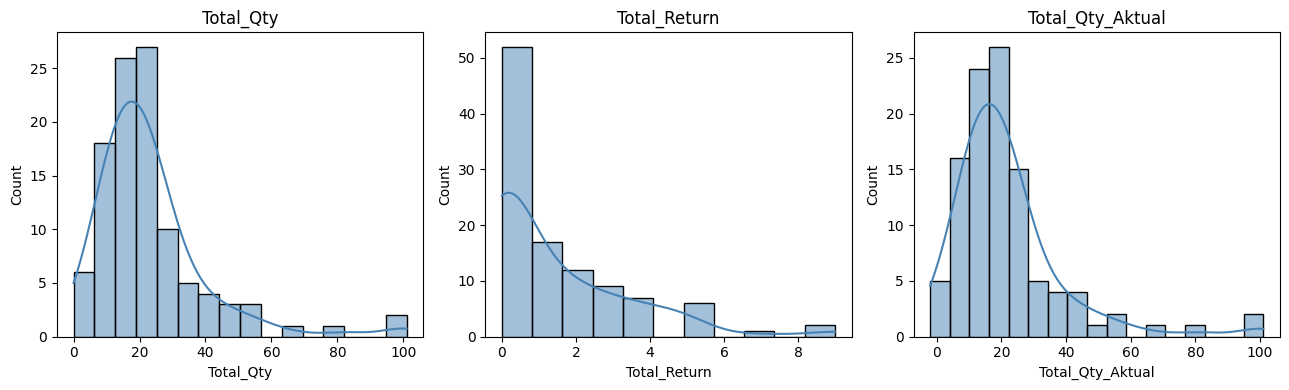

Skewness Qty Aktual: 2.375; kurtosis berlebih: 7.575.
Distribusi condong ke kanan.
Ekor relatif tebal.


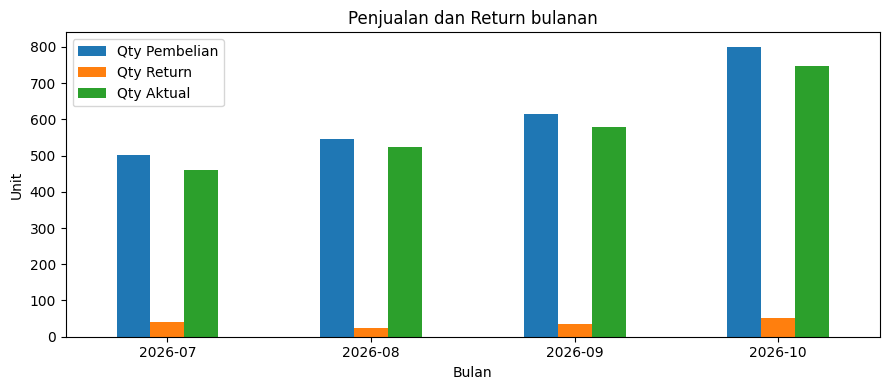

In [ ]:
display(desc[['Skewness','Kurtosis']].round(3))
fig,ax=plt.subplots(1,3,figsize=(13,4))
for c,axis in zip(cols,ax):
    sns.histplot(data=daily,x=c,kde=daily[c].nunique()>1,ax=axis,color='steelblue');axis.set_title(c)
plt.tight_layout();plt.show()
sk=daily['Total_Qty_Aktual'].skew(); ku=daily['Total_Qty_Aktual'].kurt()
print(f'Skewness Qty Aktual: {sk:.3f}; kurtosis berlebih: {ku:.3f}.')
print('Distribusi '+('condong ke kanan' if sk>0.5 else 'condong ke kiri' if sk<-.5 else 'relatif simetris menurut skewness')+'.')
print('Ekor '+('relatif tebal' if ku>0 else 'relatif tipis' if ku<0 else 'mendekati acuan normal')+'.')
monthly.plot.bar(figsize=(9,4),rot=0);plt.ylabel('Unit');plt.title('Penjualan dan Return bulanan');plt.tight_layout();plt.show()

## **BAB 6 (Transformasi Data)**


---



---



In [ ]:
train_daily=daily[daily['Tanggal_dt']<'2026-10-01'].copy()
test_daily=daily[daily['Tanggal_dt']>='2026-10-01'].copy()
assert len(train_daily)>0 and len(test_daily)>0,'Data train/test kosong'
print('Hari train:',len(train_daily),'| Hari test:',len(test_daily))

Hari train: 79 | Hari test: 27


### 6.1 Transformasi untuk memperbaiki distribusi


,Skewness
Asli,3.083
Signed log1p,-2.131


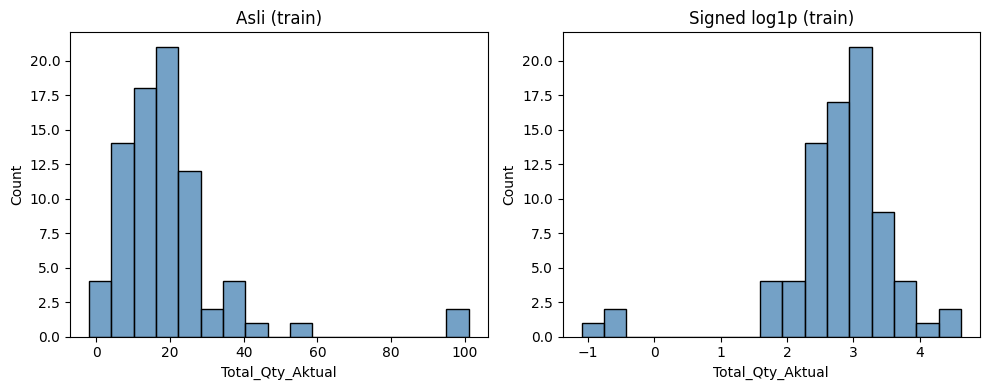

In [ ]:
s=train_daily['Total_Qty_Aktual']
transforms={'Asli':s,'Signed log1p':np.sign(s)*np.log1p(np.abs(s))}
if (s>=0).all():transforms.update({'log1p':np.log1p(s),'sqrt':np.sqrt(s)})
display(pd.DataFrame({'Skewness':{k:v.skew() for k,v in transforms.items()}}).round(3))
fig,ax=plt.subplots(1,2,figsize=(10,4));sns.histplot(s,ax=ax[0],color="steelblue");ax[0].set_title('Asli (train)');sns.histplot(transforms['Signed log1p'],ax=ax[1],color='steelblue');ax[1].set_title('Signed log1p (train)');plt.tight_layout();plt.show()

In [ ]:
sk_asli=s.skew(); sk_trans=transforms['Signed log1p'].skew()
print(f'Skewness sebelum: {sk_asli:.3f}; sesudah: {sk_trans:.3f}.')
print('Kemencengan absolut '+('berkurang' if abs(sk_trans)<abs(sk_asli) else 'tidak berkurang')+'. Ini bukan bukti normalitas.')

Skewness sebelum: 3.083; sesudah: -2.131.
Kemencengan absolut berkurang. Ini bukan bukti normalitas.


### 6.2 Transformasi skala


In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
Xtr=train_daily[['Total_Qty_Aktual']]; Xte=test_daily[['Total_Qty_Aktual']]
std=StandardScaler().fit(Xtr); mm=MinMaxScaler().fit(Xtr)
train_daily['Target_std']=std.transform(Xtr).ravel();test_daily['Target_std']=std.transform(Xte).ravel()
train_daily['Target_minmax']=mm.transform(Xtr).ravel();test_daily['Target_minmax']=mm.transform(Xte).ravel()
display(train_daily.head())

,Tanggal_dt,Total_Qty,Total_Return,Total_Qty_Aktual,Baris,Ada Catatan,Status Hari,Target_std,Target_minmax
0,2026-07-01,36.0,1.0,35.0,37.0,True,Ada transaksi,0.927269,0.359223
1,2026-07-02,22.0,1.0,21.0,23.0,True,Ada transaksi,0.073348,0.223301
2,2026-07-03,45.0,0.0,45.0,25.0,True,Ada transaksi,1.537213,0.456311
3,2026-07-04,24.0,2.0,22.0,26.0,True,Ada transaksi,0.134342,0.233010
4,2026-07-06,18.0,0.0,18.0,18.0,True,Ada transaksi,-0.109635,0.194175


In [ ]:
display(pd.DataFrame({'Mean train':train_daily[['Target_std','Target_minmax']].mean(),'Std train (populasi)':train_daily[['Target_std','Target_minmax']].std(ddof=0),'Min train':train_daily[['Target_std','Target_minmax']].min(),'Max train':train_daily[['Target_std','Target_minmax']].max()}).round(3))

,Mean train,Std train (populasi),Min train,Max train
Target_std,0.000,1.000,-1.33,4.953
Target_minmax,0.212,0.159,0.00,1.000


### 6.3 Konversi data kategorikal (categorical encoding)


In [ ]:
hari_kategori=pd.Categorical(daily['Tanggal_dt'].dt.dayofweek,categories=list(range(7)))
encoding_hari=pd.get_dummies(hari_kategori,prefix='Hari_Minggu',dtype=int)
display(encoding_hari.head())

,Hari_Minggu_0,Hari_Minggu_1,Hari_Minggu_2,Hari_Minggu_3,Hari_Minggu_4,Hari_Minggu_5,Hari_Minggu_6
0,0,0,1,0,0,0,0
1,0,0,0,1,0,0,0
2,0,0,0,0,1,0,0
3,0,0,0,0,0,1,0
4,1,0,0,0,0,0,0


### 6.4 Pembuatan fitur baru (feature engineering)


In [ ]:
fitur=daily[['Tanggal_dt','Total_Qty_Aktual']].copy()
fitur['Hari_ke']=(fitur['Tanggal_dt']-MULAI).dt.days
fitur['Bulan']=fitur['Tanggal_dt'].dt.month
fitur['Tanggal_dalam_bulan']=fitur['Tanggal_dt'].dt.day
fitur['Is_Weekend']=fitur['Tanggal_dt'].dt.dayofweek.isin([5,6]).astype(int)
for lag in [1,7]:
    prev=daily[['Tanggal_dt','Total_Qty_Aktual']].copy()
    prev['Tanggal_dt']+=pd.Timedelta(days=lag)
    prev=prev.rename(columns={'Total_Qty_Aktual':f'Lag_{lag}'})
    fitur=fitur.merge(prev,on='Tanggal_dt',how='left',validate='one_to_one')
prev=daily[['Tanggal_dt','Total_Qty','Total_Return']].copy()
prev['Rasio_Return_Lag1']=prev['Total_Return']/prev['Total_Qty'].replace(0,np.nan)
prev['Tanggal_dt']+=pd.Timedelta(days=1)
fitur=fitur.merge(prev[['Tanggal_dt','Rasio_Return_Lag1']],on='Tanggal_dt',how='left',validate='one_to_one')
fitur=pd.concat([fitur,encoding_hari.set_axis(fitur.index)],axis=1)
display(fitur.head(10)); print('Fitur historis kosong:',fitur[['Lag_1','Lag_7','Rasio_Return_Lag1']].isna().sum().to_dict())
fitur.to_csv('fitur_harian_kandidat.csv',index=False)

,Tanggal_dt,Total_Qty_Aktual,Hari_ke,Bulan,Tanggal_dalam_bulan,Is_Weekend,Lag_1,Lag_7,Rasio_Return_Lag1,Hari_Minggu_0,Hari_Minggu_1,Hari_Minggu_2,Hari_Minggu_3,Hari_Minggu_4,Hari_Minggu_5,Hari_Minggu_6
0,2026-07-01,35.0,0,7,1,0,NaN,NaN,NaN,0,0,1,0,0,0,0
1,2026-07-02,21.0,1,7,2,0,35.0,NaN,0.027778,0,0,0,1,0,0,0
2,2026-07-03,45.0,2,7,3,0,21.0,NaN,0.045455,0,0,0,0,1,0,0
3,2026-07-04,22.0,3,7,4,1,45.0,NaN,0.000000,0,0,0,0,0,1,0
4,2026-07-06,18.0,5,7,6,0,NaN,NaN,NaN,1,0,0,0,0,0,0
5,2026-07-07,16.0,6,7,7,0,18.0,NaN,0.000000,0,1,0,0,0,0,0
6,2026-07-08,-1.0,7,7,8,0,16.0,35.0,0.000000,0,0,1,0,0,0,0
7,2026-07-09,9.0,8,7,9,0,-1.0,21.0,1.125000,0,0,0,1,0,0,0
8,2026-07-10,11.0,9,7,10,0,9.0,45.0,0.000000,0,0,0,0,1,0,0
9,2026-07-11,9.0,10,7,11,1,11.0,22.0,0.000000,0,0,0,0,0,1,0


Fitur historis kosong: {'Lag_1': 18, 'Lag_7': 9, 'Rasio_Return_Lag1': 20}


## **BAB 7 (isualisasi Hubungan Data)**


---



---



### 7.1 Analisis distribusi variabel tunggal (univariate)

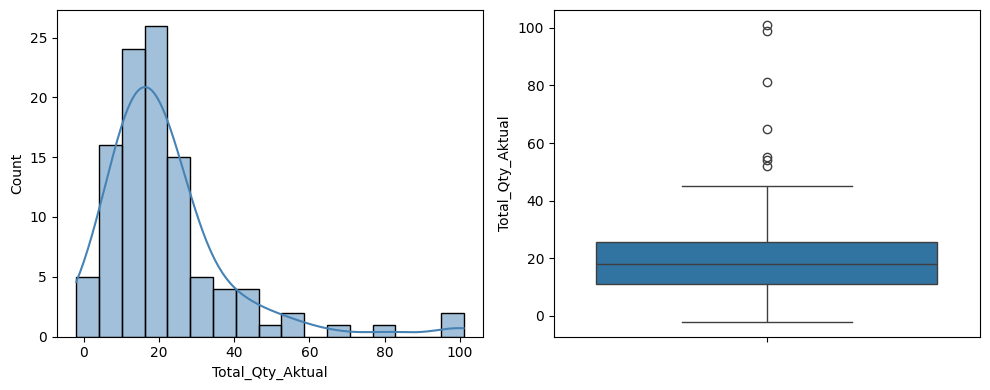

,Baris,Qty_Aktual,Persen baris,Persen unit bersih
Platform,,,,
Shopee,1310,1162.0,58.22,50.26
TikTok,680,526.0,30.22,22.75
WhatsApp,260,624.0,11.56,26.99


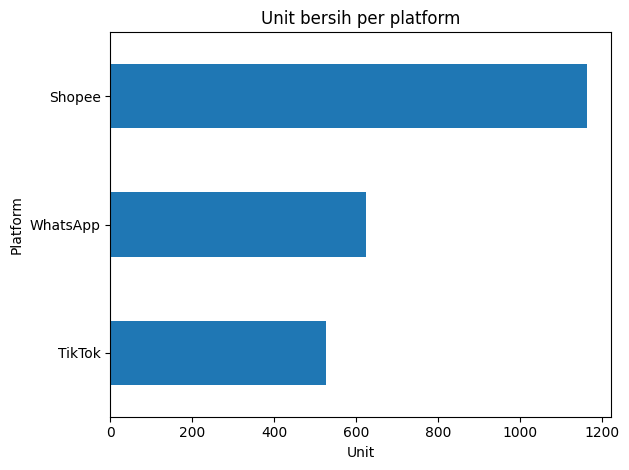

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.histplot(daily['Total_Qty_Aktual'],kde=True,ax=ax[0],color='steelblue');sns.boxplot(y=daily['Total_Qty_Aktual'],ax=ax[1]);plt.tight_layout();plt.show()
kanal_ringkas=a.groupby('Platform').agg(Baris=('ID Baris','size'),Qty_Aktual=('Qty Aktual','sum'))
kanal_ringkas['Persen baris']=100*kanal_ringkas['Baris']/len(a)
kanal_ringkas['Persen unit bersih']=100*kanal_ringkas['Qty_Aktual']/kanal_ringkas['Qty_Aktual'].sum() if kanal_ringkas['Qty_Aktual'].sum()!=0 else np.nan
display(kanal_ringkas.round(2))
kanal_ringkas['Qty_Aktual'].sort_values().plot.barh(title='Unit bersih per platform');plt.xlabel('Unit');plt.tight_layout();plt.show()

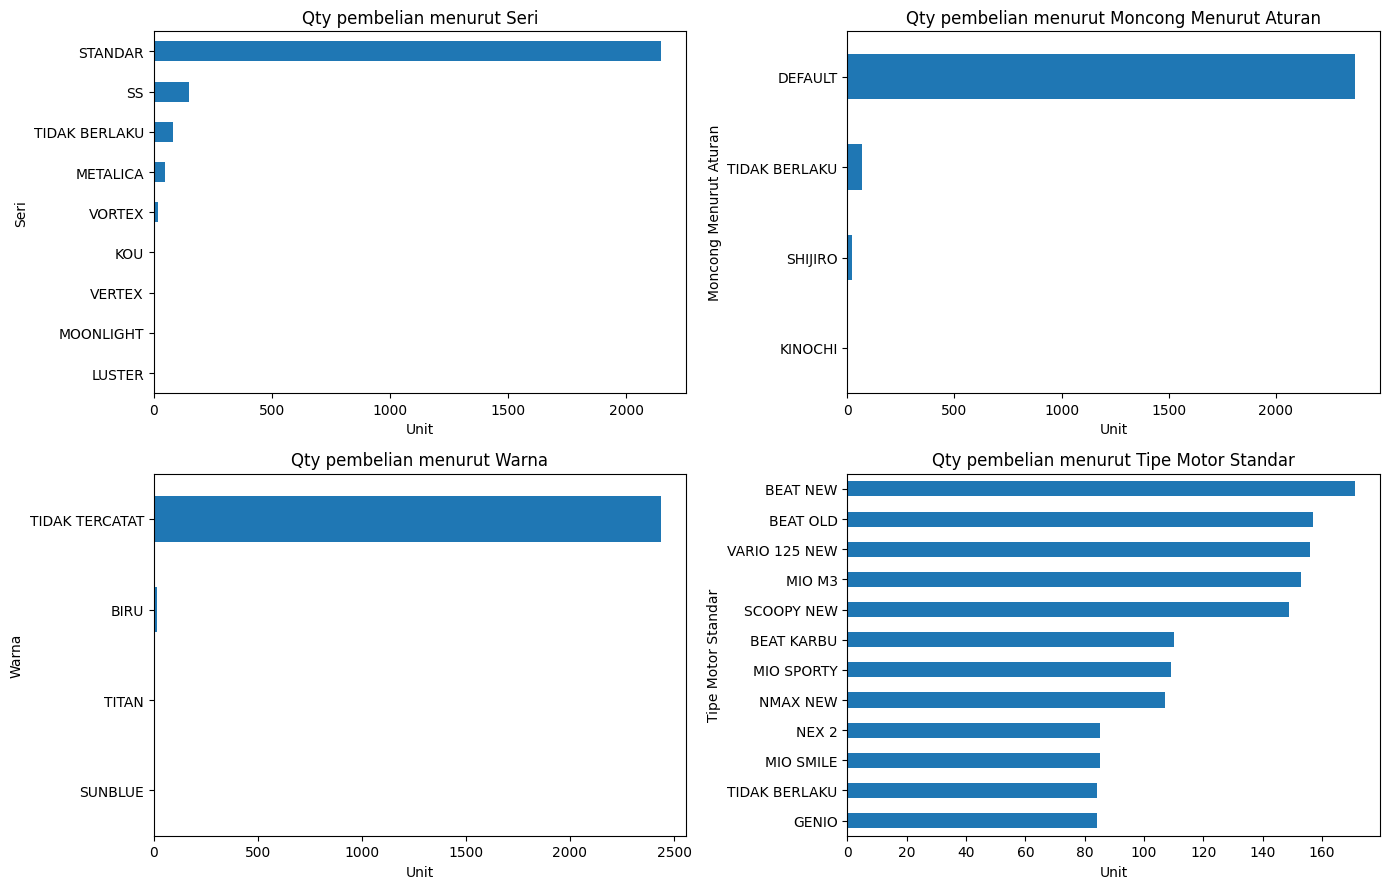

In [ ]:
fig,ax=plt.subplots(2,2,figsize=(14,9))
for axis,col in zip(ax.flat,['Seri','Moncong Menurut Aturan','Warna','Tipe Motor Standar']):
    a.groupby(col)['Qty Pembelian'].sum().nlargest(12).sort_values().plot.barh(ax=axis)
    axis.set_title('Qty pembelian menurut '+col);axis.set_xlabel('Unit')
plt.tight_layout();plt.show()

### 7.2 Analisis hubungan antarvariabel (bivariate dan multivariate)


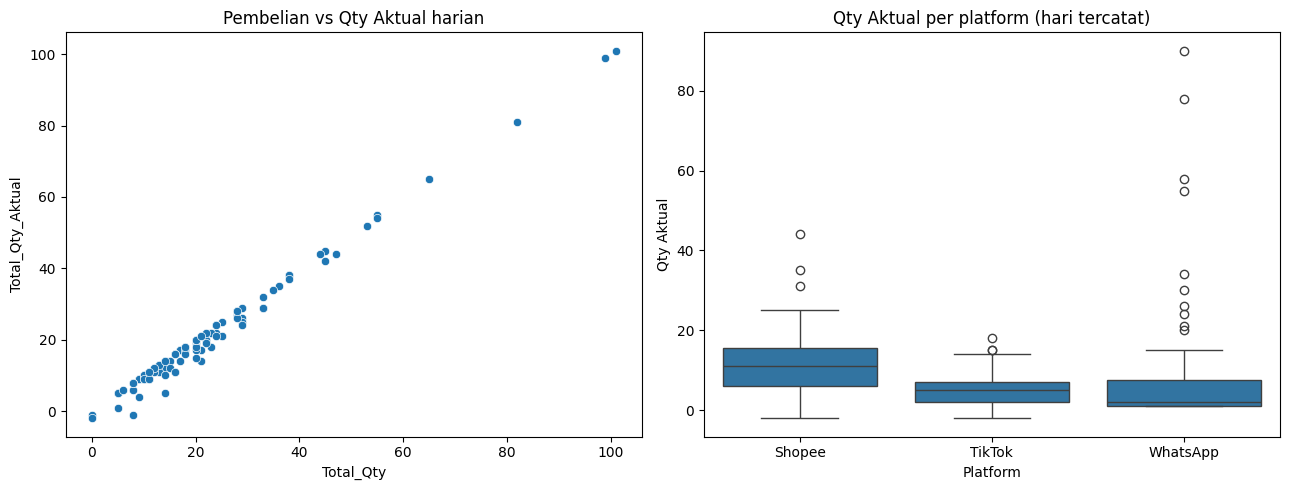

In [ ]:
qty_platform_harian=a.groupby(['Tanggal_dt','Platform'])['Qty Aktual'].sum().reset_index()
fig,ax=plt.subplots(1,2,figsize=(13,5))
sns.scatterplot(data=daily,x='Total_Qty',y='Total_Qty_Aktual',ax=ax[0]);ax[0].set_title('Pembelian vs Qty Aktual harian')
sns.boxplot(data=qty_platform_harian,x='Platform',y='Qty Aktual',ax=ax[1]);ax[1].set_title('Qty Aktual per platform (hari tercatat)')
plt.tight_layout();plt.show()

### 7.3 Analisis korelasi dan asosiasi


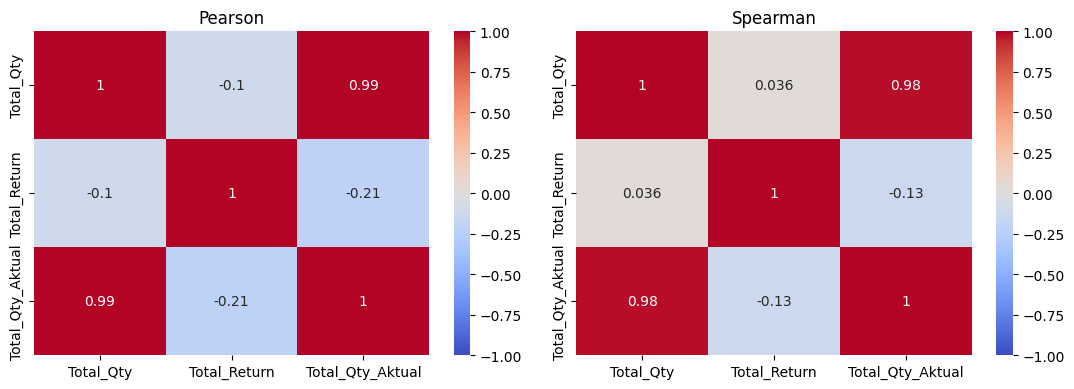

Korelasi aritmetika Qty Pembelian vs Qty Aktual: 0.994


,Fitur,Pearson,Spearman,Jumlah pasangan
0,Hari_ke,0.125,0.109,79
1,Bulan,0.111,0.099,79
2,Is_Weekend,-0.189,-0.190,79
3,Lag_1,-0.088,-0.076,65
4,Lag_7,0.279,0.164,70
5,Rasio_Return_Lag1,-0.016,-0.021,63


In [ ]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
for metode,axis in zip(['pearson','spearman'],ax):
    sns.heatmap(daily[cols].corr(method=metode),annot=True,cmap='coolwarm',vmin=-1,vmax=1,ax=axis);axis.set_title(metode.title())
plt.tight_layout();plt.show()
print('Korelasi aritmetika Qty Pembelian vs Qty Aktual:',round(daily['Total_Qty'].corr(daily['Total_Qty_Aktual']),3))
ftr=fitur[fitur['Tanggal_dt']<pd.Timestamp('2026-10-01')]
kor_hist=pd.DataFrame([{'Fitur':c,'Pearson':ftr[c].corr(ftr['Total_Qty_Aktual']),'Spearman':ftr[c].corr(ftr['Total_Qty_Aktual'],method='spearman'),'Jumlah pasangan':ftr[[c,'Total_Qty_Aktual']].dropna().shape[0]} for c in ['Hari_ke','Bulan','Is_Weekend','Lag_1','Lag_7','Rasio_Return_Lag1']])
display(kor_hist.round(3))

## **BAB 8 (Penanganan Pencilan)**


---



---



### 8.1 Metode deteksi pencilan


Batas IQR train: -8.5 43.5


,Tanggal_dt,Total_Qty,Total_Return,Total_Qty_Aktual,Baris,Ada Catatan,Status Hari,Outlier_IQR,Outlier_Z
2,2026-07-03,45.0,0.0,45.0,25.0,True,Ada transaksi,True,False
46,2026-08-25,99.0,0.0,99.0,18.0,True,Ada transaksi,True,True
64,2026-09-14,101.0,0.0,101.0,38.0,True,Ada transaksi,True,True
70,2026-09-21,55.0,0.0,55.0,29.0,True,Ada transaksi,True,False
82,2026-10-05,53.0,1.0,52.0,54.0,True,Ada transaksi,True,False
83,2026-10-06,55.0,1.0,54.0,39.0,True,Ada transaksi,True,False
87,2026-10-10,44.0,0.0,44.0,44.0,True,Ada transaksi,True,False
88,2026-10-12,47.0,3.0,44.0,50.0,True,Ada transaksi,True,False
95,2026-10-20,82.0,1.0,81.0,38.0,True,Ada transaksi,True,True
102,2026-10-28,65.0,0.0,65.0,47.0,True,Ada transaksi,True,False


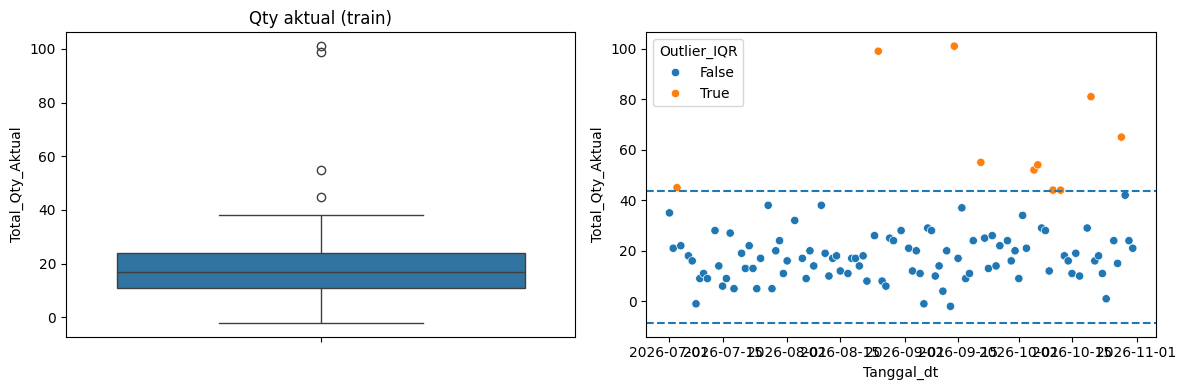

In [ ]:
s=train_daily['Total_Qty_Aktual']; q1,q3=s.quantile([.25,.75]);iqr=q3-q1
low=q1-1.5*iqr; high=q3+1.5*iqr
sd=s.std(ddof=0)
daily['Outlier_IQR']=(daily['Total_Qty_Aktual']<low)|(daily['Total_Qty_Aktual']>high)
daily['Outlier_Z']=((daily['Total_Qty_Aktual']-s.mean()).abs()/sd>3) if sd>0 else False
print('Batas IQR train:',low,high)
display(daily[daily['Outlier_IQR']|daily['Outlier_Z']])
fig,ax=plt.subplots(1,2,figsize=(12,4));sns.boxplot(y=s,ax=ax[0]);ax[0].set_title('Qty aktual (train)');sns.scatterplot(data=daily,x='Tanggal_dt',y='Total_Qty_Aktual',hue='Outlier_IQR',ax=ax[1]);ax[1].axhline(high,ls='--');ax[1].axhline(low,ls='--');plt.tight_layout();plt.show()

### 8.2 Keputusan perlakuan terhadap pencilan


In [ ]:
print('Outlier IQR:',int(daily['Outlier_IQR'].sum()),'| Outlier Z-score:',int(daily['Outlier_Z'].sum()))
print('Baris harian sebelum dan sesudah perlakuan:',len(daily),len(daily),'(retention)')
display(daily.loc[daily['Outlier_IQR']|daily['Outlier_Z'],['Tanggal_dt','Total_Qty','Total_Return','Total_Qty_Aktual','Outlier_IQR','Outlier_Z']])

Outlier IQR: 10 | Outlier Z-score: 3
Baris harian sebelum dan sesudah perlakuan: 106 106 (retention)


,Tanggal_dt,Total_Qty,Total_Return,Total_Qty_Aktual,Outlier_IQR,Outlier_Z
2,2026-07-03,45.0,0.0,45.0,True,False
46,2026-08-25,99.0,0.0,99.0,True,True
64,2026-09-14,101.0,0.0,101.0,True,True
70,2026-09-21,55.0,0.0,55.0,True,False
82,2026-10-05,53.0,1.0,52.0,True,False
83,2026-10-06,55.0,1.0,54.0,True,False
87,2026-10-10,44.0,0.0,44.0,True,False
88,2026-10-12,47.0,3.0,44.0,True,False
95,2026-10-20,82.0,1.0,81.0,True,True
102,2026-10-28,65.0,0.0,65.0,True,False


## **BAB 9 (Kesimpulan & Temuan Utama)**

### 9.1 Rangkuman temuan utama


#### 9.1.1 Evaluasi baseline regresi harian

Baseline mean: 19.80 unit/hari
MAE: 13.95 unit | RMSE: 20.16 unit


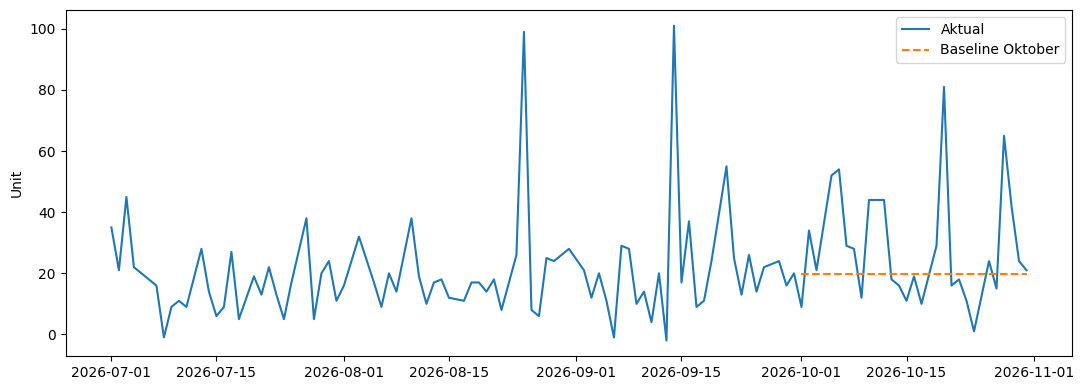

In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
mean_train=train_daily['Total_Qty_Aktual'].mean()
y_true=test_daily['Total_Qty_Aktual'].to_numpy()
y_pred=np.full(len(y_true),mean_train)
mae=mean_absolute_error(y_true,y_pred);rmse=np.sqrt(mean_squared_error(y_true,y_pred))
print(f'Baseline mean: {mean_train:.2f} unit/hari')
print(f'MAE: {mae:.2f} unit | RMSE: {rmse:.2f} unit')
fig,ax=plt.subplots(figsize=(11,4));ax.plot(daily['Tanggal_dt'],daily['Total_Qty_Aktual'],label='Aktual');ax.plot(test_daily['Tanggal_dt'],y_pred,label='Baseline Oktober',ls='--');ax.legend();ax.set_ylabel('Unit');plt.tight_layout();plt.show()

#### 9.1.2 Ringkasan volume dan rekap penjualan

In [ ]:
import pandas as pd
import numpy as np

print("=" * 65)
print("RINGKASAN HASIL AKHIR EDA NDR RACING")
print("PERIODE JULI - OKTOBER 2026")
print("=" * 65)

# 1. Ringkasan hasil pengolahan data
ringkasan_final = pd.DataFrame([
    ['Jumlah baris sebelum cleaning', len(df_raw)],
    ['Jumlah kolom sebelum cleaning', df_raw.shape[1]],
    ['Jumlah baris setelah cleaning', len(df)],
    ['Jumlah kolom setelah cleaning', df.shape[1]],
    ['Baris yang dapat dianalisis', len(a)],
    ['Baris masih perlu review', df['Perlu Review'].sum()],
    ['Tanggal tidak valid', (~df['Tanggal_dt'].between(
        '2026-07-01', '2026-10-31')).sum()],
    ['Platform kosong', df['Platform'].isna().sum()],
    ['Konflik platform', df['Konflik Platform'].sum()],
    ['Qty kosong', df['Qty'].isna().sum()],
    ['Total Qty Pembelian', a['Qty Pembelian'].sum()],
    ['Total Qty Return', a['Qty Return'].sum()],
    ['Total Qty Aktual', a['Qty Aktual'].sum()],
    ['Jumlah hari tercatat', len(daily)],
    ['Jumlah hari data latih', len(train_daily)],
    ['Jumlah hari data uji', len(test_daily)],
    ['Rata-rata penjualan harian', round(
        daily['Total_Qty_Aktual'].mean(), 2)],
    ['Penjualan harian tertinggi',
        daily['Total_Qty_Aktual'].max()],
    ['Penjualan harian terendah',
        daily['Total_Qty_Aktual'].min()],
    ['Outlier IQR', daily['Outlier_IQR'].sum()],
    ['Outlier Z-Score', daily['Outlier_Z'].sum()],
    ['Baseline Mean', round(mean_train, 2)],
    ['Baseline MAE', round(mae, 2)],
    ['Baseline RMSE', round(rmse, 2)]
], columns=['Indikator', 'Hasil'])

display(ringkasan_final)
print('Status: KANDIDAT — rekonsiliasi dan konflik atribut diperiksa sebelum final.')

RINGKASAN HASIL AKHIR EDA NDR RACING
PERIODE JULI - OKTOBER 2026


,Indikator,Hasil
0,Jumlah baris sebelum cleaning,2324.00
1,Jumlah kolom sebelum cleaning,9.00
2,Jumlah baris setelah cleaning,2250.00
3,Jumlah kolom setelah cleaning,58.00
4,Baris yang dapat dianalisis,2250.00
5,Baris masih perlu review,2071.00
6,Tanggal tidak valid,0.00
7,Platform kosong,0.00
8,Konflik platform,0.00
9,Qty kosong,0.00


Status: KANDIDAT — rekonsiliasi dan konflik atribut diperiksa sebelum final.


In [ ]:
rekap_final_bulan = a.groupby('Bulan').agg(
    Jumlah_Baris=('ID Baris', 'count'),
    Qty_Pembelian=('Qty Pembelian', 'sum'),
    Qty_Return=('Qty Return', 'sum'),
    Qty_Aktual=('Qty Aktual', 'sum')
)

rekap_final_bulan.loc['TOTAL'] = (
    rekap_final_bulan.sum()
)

display(rekap_final_bulan)

,Jumlah_Baris,Qty_Pembelian,Qty_Return,Qty_Aktual
Bulan,,,,
2026-07,495.0,501.0,40.0,461.0
2026-08,475.0,546.0,23.0,523.0
2026-09,537.0,616.0,36.0,580.0
2026-10,743.0,800.0,52.0,748.0
TOTAL,2250.0,2463.0,151.0,2312.0


In [ ]:
rekap_final_platform = a.groupby('Platform').agg(
    Jumlah_Baris=('ID Baris', 'count'),
    Qty_Pembelian=('Qty Pembelian', 'sum'),
    Qty_Return=('Qty Return', 'sum'),
    Qty_Aktual=('Qty Aktual', 'sum')
)

rekap_final_platform.loc['TOTAL'] = (
    rekap_final_platform.sum()
)

display(rekap_final_platform)

,Jumlah_Baris,Qty_Pembelian,Qty_Return,Qty_Aktual
Platform,,,,
Shopee,1310.0,1236.0,74.0,1162.0
TikTok,680.0,603.0,77.0,526.0
WhatsApp,260.0,624.0,0.0,624.0
TOTAL,2250.0,2463.0,151.0,2312.0


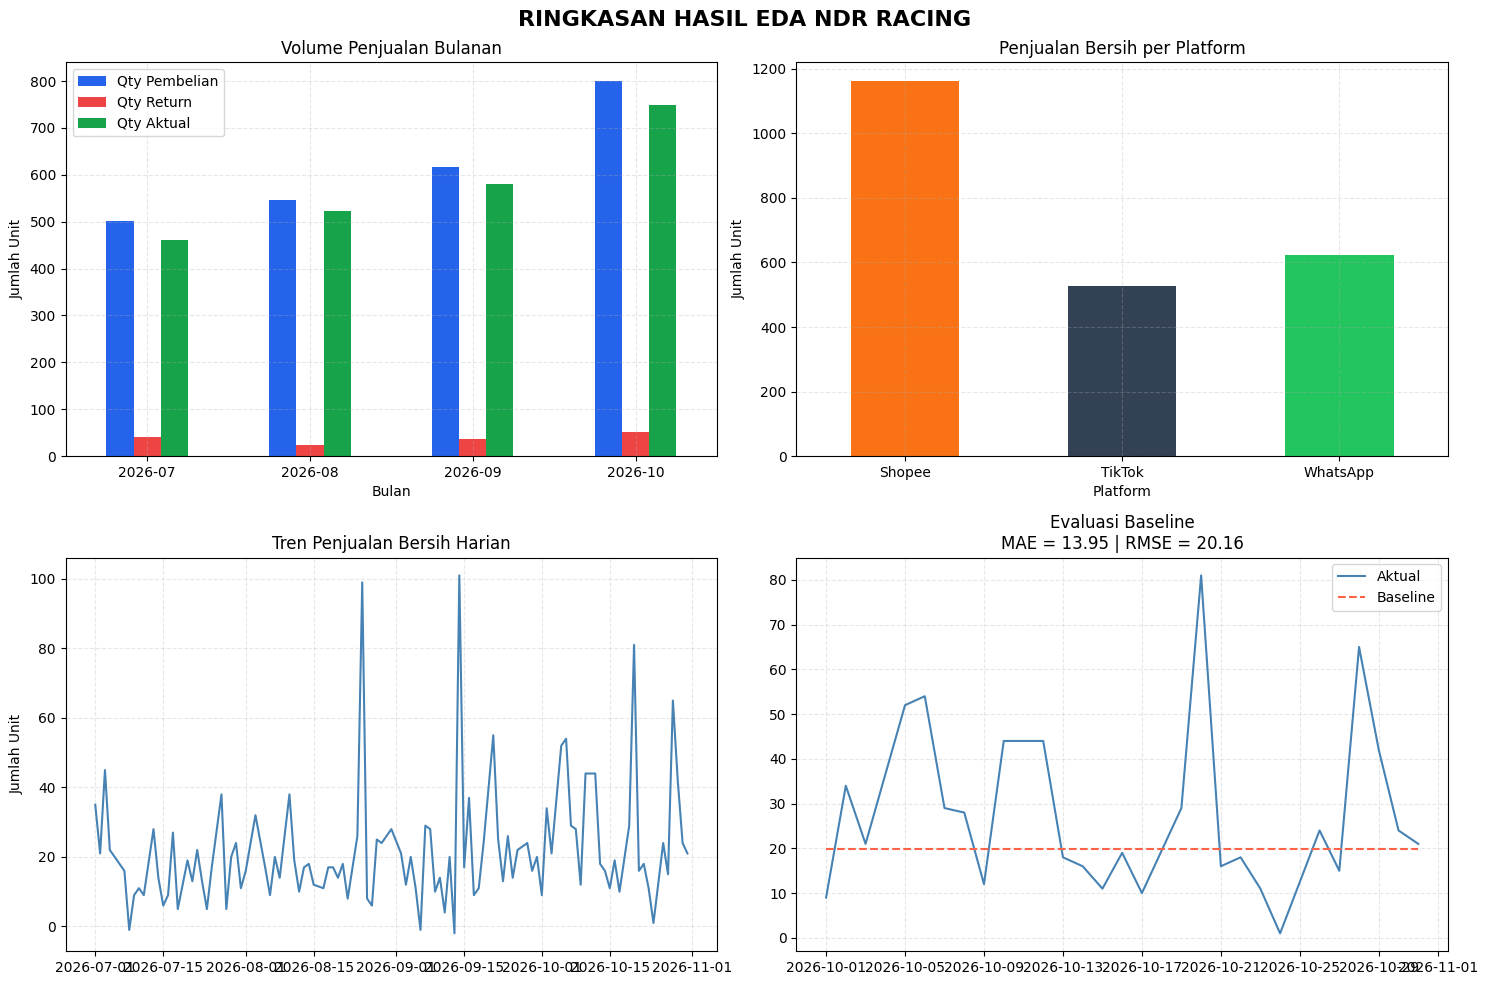

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# Grafik 1: Penjualan bulanan
monthly.plot.bar(
    ax=ax[0, 0],
    color=['#2563eb', '#ef4444', '#16a34a'],
    rot=0
)

ax[0, 0].set_title('Volume Penjualan Bulanan')
ax[0, 0].set_ylabel('Jumlah Unit')

# Grafik 2: Penjualan per platform
platform_final = a.groupby('Platform')[
    'Qty Aktual'
].sum()

platform_final.plot.bar(
    ax=ax[0, 1],
    color=['#f97316', '#334155', '#22c55e'],
    rot=0
)

ax[0, 1].set_title('Penjualan Bersih per Platform')
ax[0, 1].set_ylabel('Jumlah Unit')

# Grafik 3: Tren penjualan harian
ax[1, 0].plot(
    daily['Tanggal_dt'],
    daily['Total_Qty_Aktual'],
    color='steelblue'
)

ax[1, 0].set_title('Tren Penjualan Bersih Harian')
ax[1, 0].set_ylabel('Jumlah Unit')

# Grafik 4: Evaluasi baseline
ax[1, 1].plot(
    test_daily['Tanggal_dt'],
    y_true,
    label='Aktual',
    color='steelblue'
)

ax[1, 1].plot(
    test_daily['Tanggal_dt'],
    y_pred,
    label='Baseline',
    color='tomato',
    linestyle='--'
)

ax[1, 1].set_title(
    f'Evaluasi Baseline\nMAE = {mae:.2f} | RMSE = {rmse:.2f}'
)

ax[1, 1].legend()

for axis in ax.flat:
    axis.grid(alpha=0.3, linestyle='--')

plt.suptitle(
    'RINGKASAN HASIL EDA NDR RACING',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [ ]:
bulan_top=monthly['Qty Aktual'].idxmax(); platform_top=a.groupby('Platform')['Qty Aktual'].sum().idxmax()
net=a['Qty Aktual'].sum(); pnet=a.groupby('Platform')['Qty Aktual'].sum()
hari_top=daily.loc[daily['Total_Qty_Aktual'].idxmax()]
print(f'Total {net:,.0f} unit bersih dari {len(a):,} baris yang dapat dianalisis.')
print(f'Bulan tertinggi: {bulan_top}, {monthly.loc[bulan_top,"Qty Aktual"]:.0f} unit.')
print(f'Kanal dominan: {platform_top}, {pnet[platform_top]:.0f} unit ({100*pnet[platform_top]/net:.2f}% dari net).')
print(f'Hari tertinggi: {hari_top["Tanggal_dt"]:%d-%m-%Y}, {hari_top["Total_Qty_Aktual"]:.0f} unit.')
print(f'Jumlah hari net negatif: {daily["Total_Qty_Aktual"].lt(0).sum()}.')
print(f'Baseline MAE {mae:.2f} unit; RMSE {rmse:.2f} unit.')
k=kor_hist.dropna(subset=['Pearson'])
if not k.empty:
    r=k.loc[k['Pearson'].abs().idxmax()]
    print(f'Korelasi Pearson absolut terbesar antara kandidat fitur dan target (train): {r["Fitur"]}, r={r["Pearson"]:.3f}, n={r["Jumlah pasangan"]}. Temuan eksploratif, bukan bukti prediktif.')
print('Distribusi kategori produk (unit bersih):')
display(a.groupby('Kategori Produk')['Qty Aktual'].sum().sort_values(ascending=False).to_frame())
print(f'Pencilan IQR: {int(daily["Outlier_IQR"].sum())} hari; Z-score: {int(daily["Outlier_Z"].sum())} hari (ambang dari train).')
print(f'Skewness target: {daily["Total_Qty_Aktual"].skew():.3f}; kurtosis berlebih: {daily["Total_Qty_Aktual"].kurt():.3f}.')

Total 2,312 unit bersih dari 2,250 baris yang dapat dianalisis.
Bulan tertinggi: 2026-10, 748 unit.
Kanal dominan: Shopee, 1162 unit (50.26% dari net).
Hari tertinggi: 14-09-2026, 101 unit.
Jumlah hari net negatif: 3.
Baseline MAE 13.95 unit; RMSE 20.16 unit.
Korelasi Pearson absolut terbesar antara kandidat fitur dan target (train): Lag_7, r=0.279, n=70. Temuan eksploratif, bukan bukti prediktif.
Distribusi kategori produk (unit bersih):


,Qty Aktual
Kategori Produk,
KNALPOT,2229.0
AKSESORI,83.0


Pencilan IQR: 10 hari; Z-score: 3 hari (ambang dari train).
Skewness target: 2.375; kurtosis berlebih: 7.575.


### 9.2 Keterbatasan dan kendala analisis


In [ ]:
# Catatan keterbatasan dihitung dari hasil aktual, bukan tabel audit tambahan.
print(f'Selisih baris CSV vs kandidat PDF: {len(df_raw)-len(df_pdf)}; kelompok resi/status berbeda: {len(selisih)}.')
print(f'Qty diimputasi: {int(df["Qty Metode"].str.startswith("Imputasi",na=False).sum())} baris.')
print(f'Hari tanpa catatan: {int((~kalender["Ada Catatan"]).sum())}; hari dianalisis: {len(daily)}.')
print(f'Konflik atribut seri: {int(df["Konflik Atribut Seri"].sum())}; review inti: {int(df["Perlu Review Inti"].sum())}.')
print(f'Selisih Qty rincian vs total tertulis bagian WhatsApp Oktober: {audit_qty_wa.loc["oct","Selisih Qty"]:.0f} unit.')

Selisih baris CSV vs kandidat PDF: 64; kelompok resi/status berbeda: 7.
Qty diimputasi: 690 baris.
Hari tanpa catatan: 17; hari dianalisis: 106.
Konflik atribut seri: 2071; review inti: 0.
Selisih Qty rincian vs total tertulis bagian WhatsApp Oktober: 2 unit.


### 9.3 Rekomendasi langkah selanjutnya

Berdasarkan hasil EDA, data penjualan NDR Racing memiliki distribusi yang tidak simetris, fluktuasi penjualan harian, serta pencilan yang dipertahankan sesuai karakteristik bisnis. Oleh karena itu, model yang direkomendasikan untuk tahap prediksi adalah:

- **Random Forest Regressor:** sebagai kandidat utama karena mampu menangkap hubungan nonlinier dan relatif tangguh terhadap pencilan.
- **Gradient Boosting Regressor:** sebagai alternatif untuk mempelajari pola dan interaksi antarfitur.
- **Linear Regression dan Ridge Regression:** sebagai model pembanding untuk mengevaluasi hubungan linear antarvariabel.

Pengembangan model dapat menggunakan fitur waktu, hari dalam minggu, Lag 1, Lag 7, serta rasio Return historis. Penambahan data promosi, hari libur, kampanye marketplace, dan riwayat penjualan yang lebih panjang juga direkomendasikan untuk meningkatkan kualitas prediksi.

Evaluasi model dilakukan secara kronologis menggunakan MAE dan RMSE dengan nilai baseline masing-masing sebesar 13,95 dan 20,16 unit. Model terbaik dipilih berdasarkan kemampuan menghasilkan kesalahan prediksi yang lebih rendah pada data uji.


### 9.4 Ringkasan Return dan ekspor publik


In [ ]:
ret=a.groupby('Platform')[['Qty Pembelian','Qty Return','Qty Aktual']].sum()
ret['Rasio Return terhadap Qty Pembelian (%)']=(100*ret['Qty Return']/ret['Qty Pembelian'].replace(0,np.nan)).round(2)
display(ret)
daily.to_csv('rekap_ndr_harian_kandidat_1.csv',index=False,encoding='utf-8-sig')
monthly.to_csv('rekap_ndr_bulanan_kandidat_1.csv',encoding='utf-8-sig')
# Versi publik: resi dan nama asli tidak diekspor.
public_cols=['Tanggal_dt','Platform','Kategori Produk','Seri','Moncong Menurut Aturan','Sarangan','Warna','Tipe Motor Standar','Pabrikan','Qty Pembelian','Qty Return','Qty Aktual','Keterangan','Perlu Review']
df[public_cols].to_csv('rekap_ndr_publik_kandidat_1.csv',index=False,encoding='utf-8-sig')
print('File CSV berhasil dibuat. Gunakan hasil sebagai kandidat sampai validasi selesai.')
# Jika ingin mengunduh hasil publik saja:
# files.download('rekap_ndr_publik_kandidat_1.csv')
# Agregat harian untuk repositori setelah izin perusahaan.
daily[['Tanggal_dt','Total_Qty','Total_Return','Total_Qty_Aktual']].to_csv('ndr_harian_untuk_github.csv',index=False,encoding='utf-8-sig')

,Qty Pembelian,Qty Return,Qty Aktual,Rasio Return terhadap Qty Pembelian (%)
Platform,,,,
Shopee,1236.0,74.0,1162.0,5.99
TikTok,603.0,77.0,526.0,12.77
WhatsApp,624.0,0.0,624.0,0.00


File CSV berhasil dibuat. Gunakan hasil sebagai kandidat sampai validasi selesai.


### 9.5 Ringkasan audit sebelum dan sesudah cleaning

In [ ]:
# 9.5 RINGKASAN 12 TEMUAN AUDIT FINAL

import pandas as pd
import numpy as np

MULAI = pd.Timestamp('2026-07-01')
AKHIR = pd.Timestamp('2026-10-31')

# Mengambil hasil audit data mentah BAB 2.3
if 'ringkasan_audit' not in globals():
    ringkasan_audit = pd.read_csv(
        'audit_sebelum_cleaning.csv'
    )

awal = dict(zip(
    ringkasan_audit['Temuan'],
    ringkasan_audit['Jumlah']
))

# Persiapan pemeriksaan data setelah cleaning
q = pd.to_numeric(df['Qty'], errors='coerce')
tg = df['Tanggal_dt']

# Pemeriksaan duplikasi identik
kol_duplikat = [
    'Tanggal_dt',
    'Platform',
    'Nomor Resi',
    'Kategori Produk',
    'Seri',
    'Moncong',
    'Sarangan',
    'Tipe Motor Standar',
    'Qty',
    'Keterangan'
]

baris_identik = int(
    df.duplicated(
        kol_duplikat,
        keep=False
    ).sum()
)

# Pemeriksaan moncong ganda
mon_ganda = (
    df['Moncong'].str.contains(
        'SHIJIRO', na=False
    ) &
    df['Moncong'].str.contains(
        'KINOCHI', na=False
    )
)

# Pemeriksaan Return tanpa pasangan
ret_tanpa = int((
    df['Keterangan'].eq('RETURN') &
    df['Status Pasangan Return'].ne(
        'Pasangan ditemukan'
    )
).sum())

# ==========================================
# RINGKASAN 12 TEMUAN AUDIT
# ==========================================

rows_audit = [

    (
        'Tanggal kosong atau tidak valid',
        int(tg.isna().sum()),
        'Pemulihan tanggal berdasarkan PDF',
        'Target 0'
    ),

    (
        'Tanggal di luar periode',
        int((
            tg.notna() &
            ~tg.between(MULAI, AKHIR)
        ).sum()),
        'Koreksi tanggal berdasarkan sumber',
        'Target 0'
    ),

    (
        'Resi konflik platform',
        int(df.loc[
            df['Konflik Platform'],
            'Nomor Resi'
        ].nunique()),
        'Pilih platform sesuai pola resi dan keluarkan salinan lintas platform',
        'Target 0'
    ),

    (
        'Resi tidak dikenali',
        int(df['Prefiks Belum Dikenal'].sum()),
        'Standardisasi pola awalan resi',
        'Target 0'
    ),

    (
        'Return tanpa pasangan',
        ret_tanpa,
        'Dipertahankan karena dapat berasal dari periode sebelumnya',
        'Dapat diterima'
    ),

    (
        'Return melebihi pembelian',
        len(return_berlebih),
        'Pemeriksaan Qty pembelian dan Return',
        'Target 0'
    ),

    (
        'Qty bermasalah',
        int((
            q.isna() |
            q.le(0) |
            q.mod(1).ne(0)
        ).sum()),
        'Pemulihan Qty PDF atau imputasi dengan penanda',
        'Target 0'
    ),

    (
        'Qty lebih dari 1',
        int(q.gt(1).sum()),
        'Dipertahankan sesuai transaksi asli',
        'Dapat diterima'
    ),

    (
        'Jenis knalpot kosong',
        int(df['Kategori Produk'].fillna('').isin([
            '',
            'TIDAK DIKETAHUI'
        ]).sum()),
        'Pemulihan dan pemisahan atribut produk',
        'Kategori produk belum diketahui'
    ),

    (
        'Tipe motor bermasalah',
        int((df['Tipe Motor Standar'].fillna('').isin(['', 'TIDAK DIKETAHUI']) | (df['Kategori Produk'].eq('KNALPOT') & df['Tipe Motor Standar'].eq('TIDAK BERLAKU'))).sum()),
        'Normalisasi kamus, pemulihan NMAX NEW dan klasifikasi 15 aksesori moncong',
        'Motor tidak diketahui tetap dipertahankan'
    ),

    (
        'Baris dalam kelompok duplikat',
        baris_identik,
        'Keluarkan salinan lintas platform dan pertahankan resi ganda satu platform',
        'Dapat diterima sesuai aturan bisnis'
    ),

    (
        'Moncong Shijiro dan Kinochi bersamaan',
        int(mon_ganda.sum()),
        'Koreksi hasil screening termasuk KINOCHI NON BAUT',
        'Target 0'
    )
]

# Membentuk tabel audit final
audit_final = pd.DataFrame([

    (
        temuan,
        awal.get(temuan, np.nan),
        perbaikan,
        jumlah,
        (
            'VALID' if jumlah == 0
            else 'PERLU REVIEW'
        ) if ket == 'Target 0' else ket
    )

    for temuan, jumlah, perbaikan, ket
    in rows_audit

], columns=[
    'Temuan',
    'Sebelum Cleaning',
    'Tindakan Perbaikan',
    'Setelah Cleaning',
    'Status'
])

print("=" * 70)
print("RINGKASAN AUDIT FINAL NDR RACING")
print("=" * 70)

# Pembaruan status berdasarkan hasil pemeriksaan aktual

temuan_validasi = [
    'Jenis knalpot kosong',
    'Tipe motor bermasalah',
    'Moncong Shijiro dan Kinochi bersamaan'
]

mask_validasi = audit_final['Temuan'].isin(
    temuan_validasi
)

audit_final.loc[mask_validasi, 'Status'] = (
    np.where(
        audit_final.loc[
            mask_validasi,
            'Setelah Cleaning'
        ].eq(0),
        'VALID',
        'PERLU REVIEW'
    )
)
display(audit_final)

RINGKASAN AUDIT FINAL NDR RACING


,Temuan,Sebelum Cleaning,Tindakan Perbaikan,Setelah Cleaning,Status
0,Tanggal kosong atau tidak valid,64,Pemulihan tanggal berdasarkan PDF,0,VALID
1,Tanggal di luar periode,5,Koreksi tanggal berdasarkan sumber,0,VALID
2,Resi konflik platform,10,Pilih platform sesuai pola resi dan keluarkan ...,0,VALID
3,Resi tidak dikenali,0,Standardisasi pola awalan resi,0,VALID
4,Return tanpa pasangan,64,Dipertahankan karena dapat berasal dari period...,63,Dapat diterima
5,Return melebihi pembelian,0,Pemeriksaan Qty pembelian dan Return,0,VALID
6,Qty bermasalah,3,Pemulihan Qty PDF atau imputasi dengan penanda,0,VALID
7,Qty lebih dari 1,87,Dipertahankan sesuai transaksi asli,82,Dapat diterima
8,Jenis knalpot kosong,169,Pemulihan dan pemisahan atribut produk,0,VALID
9,Tipe motor bermasalah,139,"Normalisasi kamus, pemulihan NMAX NEW dan klas...",0,VALID


In [ ]:
audit_final.to_csv('ringkasan_audit_sebelum_sesudah.csv',index=False,encoding='utf-8-sig')
status_dataset=('VALID' if REKONSILIASI_LENGKAP_TERVERIFIKASI and not df['Perlu Review'].any() and not belum and len(return_berlebih)==0 and audit_qty_wa['Selisih Qty'].eq(0).all() else 'KANDIDAT — perlu verifikasi')
# Pemeriksaan indikator yang wajib nol; hasil dihitung, bukan ditetapkan.
wajib_nol = audit_final.loc[audit_final['Status'].isin(['VALID','PERLU REVIEW'])]
if wajib_nol['Setelah Cleaning'].eq(0).all():
    print('Seluruh indikator audit utama yang ditargetkan nol telah terpenuhi.')
else:
    print('Masih ada indikator utama yang perlu diperiksa. Lihat tabel di atas.')
print('Status dataset:',status_dataset)

Seluruh indikator audit utama yang ditargetkan nol telah terpenuhi.
Status dataset: KANDIDAT — perlu verifikasi


### 9.5 Ringkasan Temuan Audit Sebelum dan Sesudah Cleaning

In [ ]:
# 9.5 RINGKASAN TEMUAN AUDIT FINAL

import pandas as pd
import numpy as np

MULAI = pd.Timestamp('2026-07-01')
AKHIR = pd.Timestamp('2026-10-31')

# Mengambil hasil audit sebelum cleaning
awal = dict(zip(
    ringkasan_audit['Temuan'],
    ringkasan_audit['Jumlah']
))

q = pd.to_numeric(df['Qty'], errors='coerce')
tg = df['Tanggal_dt']

# Pemeriksaan duplikasi
kol_duplikat = [
    'Tanggal_dt',
    'Platform',
    'Nomor Resi',
    'Kategori Produk',
    'Seri',
    'Moncong',
    'Sarangan',
    'Tipe Motor Standar',
    'Qty',
    'Keterangan'
]

baris_identik = df.duplicated(
    kol_duplikat,
    keep=False
).sum()

# Pemeriksaan moncong ganda
mon_ganda = (
    df['Moncong'].str.contains('SHIJIRO', na=False) &
    df['Moncong'].str.contains('KINOCHI', na=False)
)

# Pemeriksaan Return tanpa pasangan
ret_tanpa = (
    df['Keterangan'].eq('RETURN') &
    df['Status Pasangan Return'].ne('Pasangan ditemukan')
).sum()

# Pemeriksaan tipe motor
motor_masalah = (
    df['Tipe Motor Standar'].fillna('').isin([
        '',
        'TIDAK DIKETAHUI'
    ]) |
    (
        df['Kategori Produk'].eq('KNALPOT') &
        df['Tipe Motor Standar'].eq('TIDAK BERLAKU')
    )
).sum()

# ==========================================
# 12 TEMUAN AUDIT UTAMA
# ==========================================

rows_audit = [

    (
        'Tanggal kosong atau tidak valid',
        tg.isna().sum(),
        'Pemulihan tanggal berdasarkan PDF',
        True
    ),

    (
        'Tanggal di luar periode',
        (
            tg.notna() &
            ~tg.between(MULAI, AKHIR)
        ).sum(),
        'Koreksi tanggal berdasarkan sumber PDF',
        True
    ),

    (
        'Resi konflik platform',
        df.loc[
            df['Konflik Platform'],
            'Nomor Resi'
        ].nunique(),
        'Standardisasi platform berdasarkan pola resi dan seleksi duplikasi lintas platform',
        True
    ),

    (
        'Resi tidak dikenali',
        df['Prefiks Belum Dikenal'].sum(),
        'Standardisasi pola nomor resi',
        True
    ),

    (
        'Return tanpa pasangan',
        ret_tanpa,
        'Dipertahankan karena pembelian dapat berasal dari periode sebelumnya',
        False
    ),

    (
        'Return melebihi pembelian',
        len(return_berlebih),
        'Validasi Qty pembelian dan Return',
        True
    ),

    (
        'Qty bermasalah',
        (
            q.isna() |
            q.le(0) |
            q.mod(1).ne(0)
        ).sum(),
        'Pemulihan Qty berdasarkan PDF dan imputasi sesuai aturan bisnis',
        True
    ),

    (
        'Qty lebih dari 1',
        q.gt(1).sum(),
        'Dipertahankan sebagai pembelian beberapa unit',
        False
    ),

    (
        'Jenis knalpot kosong',
        df['Kategori Produk'].fillna('').isin([
            '',
            'TIDAK DIKETAHUI'
        ]).sum(),
        'Pemulihan dan standardisasi atribut produk',
        True
    ),

    (
        'Tipe motor bermasalah',
        motor_masalah,
        'Standardisasi kamus motor, koreksi NMAX NEW, dan klasifikasi 15 aksesori moncong',
        True
    ),

    (
        'Baris dalam kelompok duplikat',
        baris_identik,
        'Mengeluarkan salinan lintas platform dan mempertahankan resi ganda yang valid',
        False
    ),

    (
        'Moncong Shijiro dan Kinochi bersamaan',
        mon_ganda.sum(),
        'Koreksi berdasarkan screening termasuk KINOCHI NON BAUT',
        True
    )
]

# ==========================================
# MEMBENTUK TABEL RINGKASAN AUDIT
# ==========================================

audit_final = pd.DataFrame([

    [
        temuan,
        awal.get(temuan, np.nan),
        perbaikan,
        int(jumlah),
        (
            'VALID' if jumlah == 0
            else 'PERLU REVIEW'
        ) if wajib_nol else 'DIPERTAHANKAN'
    ]

    for temuan, jumlah, perbaikan, wajib_nol
    in rows_audit

], columns=[
    'Temuan',
    'Sebelum Cleaning',
    'Tindakan Perbaikan',
    'Setelah Cleaning',
    'Status'
])

# ==========================================
# MENAMPILKAN HASIL AUDIT
# ==========================================

print("=" * 70)
print("RINGKASAN TEMUAN AUDIT FINAL NDR RACING")
print("=" * 70)

def warna_status(nilai):

    if nilai == 'VALID':
        return 'color: green; font-weight: bold'

    elif nilai == 'PERLU REVIEW':
        return 'color: red; font-weight: bold'

    elif nilai == 'DIPERTAHANKAN':
        return 'color: blue; font-weight: bold'

    return ''

display(
    audit_final.style.map(
        warna_status,
        subset=['Status']
    ).hide(axis='index')
)

# Simpan hasil audit
audit_final.to_csv(
    'ringkasan_audit_sebelum_sesudah.csv',
    index=False,
    encoding='utf-8-sig'
)

RINGKASAN TEMUAN AUDIT FINAL NDR RACING


Temuan,Sebelum Cleaning,Tindakan Perbaikan,Setelah Cleaning,Status
Tanggal kosong atau tidak valid,64,Pemulihan tanggal berdasarkan PDF,0,VALID
Tanggal di luar periode,5,Koreksi tanggal berdasarkan sumber PDF,0,VALID
Resi konflik platform,10,Standardisasi platform berdasarkan pola resi dan seleksi duplikasi lintas platform,0,VALID
Resi tidak dikenali,0,Standardisasi pola nomor resi,0,VALID
Return tanpa pasangan,64,Dipertahankan karena pembelian dapat berasal dari periode sebelumnya,63,DIPERTAHANKAN
Return melebihi pembelian,0,Validasi Qty pembelian dan Return,0,VALID
Qty bermasalah,3,Pemulihan Qty berdasarkan PDF dan imputasi sesuai aturan bisnis,0,VALID
Qty lebih dari 1,87,Dipertahankan sebagai pembelian beberapa unit,82,DIPERTAHANKAN
Jenis knalpot kosong,169,Pemulihan dan standardisasi atribut produk,0,VALID
Tipe motor bermasalah,139,"Standardisasi kamus motor, koreksi NMAX NEW, dan klasifikasi 15 aksesori moncong",0,VALID


Berdasarkan hasil perbandingan sebelum dan sesudah data
cleaning, kualitas data mengalami peningkatan pada aspek
validitas tanggal, konsistensi platform, kuantitas transaksi,
kelengkapan atribut produk, dan standardisasi tipe motor.

Sembilan indikator yang ditargetkan bernilai nol telah
memenuhi kriteria validasi. Sementara itu, tiga indikator
lainnya tetap dipertahankan karena merupakan karakteristik
transaksi yang dapat diterima berdasarkan aturan bisnis
NDR Racing.

Hasil tersebut menunjukkan bahwa proses data cleaning
berhasil memperbaiki indikator kualitas data utama tanpa
menghilangkan informasi transaksi yang relevan.


### 9.6 Penyimpanan hasil akhir dan persiapan pengumpulan

In [ ]:
nama_file='HASIL_AKHIR_EDA_NDR_PENGERJAAN_FINAL.xlsx'
with pd.ExcelWriter(nama_file,engine='openpyxl') as writer:
    sheets={
      'Ringkasan EDA':ringkasan_final,'Validasi':validasi_final,'Audit Sebelum Sesudah':audit_final,
      'Penjualan Bulanan':rekap_final_bulan.reset_index(),'Penjualan Platform':rekap_final_platform.reset_index(),
      'Penjualan Harian':daily,'Kalender Audit':kalender.reset_index(),'Statistik Deskriptif':desc.reset_index(names='Variabel'),
      'Outlier':daily.loc[daily['Outlier_IQR']|daily['Outlier_Z']],
      'Evaluasi Baseline':pd.DataFrame({'Metrik':['Baseline Mean','MAE','RMSE'],'Hasil':[mean_train,mae,rmse]}),
      'Dataset Bersih Kandidat':df,'Duplikat Dikeluarkan':keluarkan,'Audit Lintas Platform':lintas,'Resi Ganda Dipertahankan':satu,
      'Selisih CSV PDF':selisih,'Konflik Atribut':audit_atribut,'Motor Tidak Diketahui':motor_review,'Baris Review':review,
      'Log Koreksi':log_koreksi,'Koreksi Pending':koreksi_pending,'Audit Qty WA':audit_qty_wa.reset_index(),'Status Dataset':pd.DataFrame({'Status':[status_dataset]}),'Korelasi Fitur Train':kor_hist}
    for name,data in sheets.items(): data.to_excel(writer,sheet_name=name,index=False)
print('File tersimpan:',nama_file)
print('Internal: memuat resi dan data sumber. Jangan unggah ke GitHub publik.')
try:
    from google.colab import files
    files.download(nama_file)
except ImportError:
    print('Jalankan di Google Colab untuk mengunduh otomatis.')

File tersimpan: HASIL_AKHIR_EDA_NDR_PENGERJAAN_FINAL.xlsx
Internal: memuat resi dan data sumber. Jangan unggah ke GitHub publik.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

EXPORT VISUALISASI TO PNG

In [ ]:
import json
import base64
import os
import shutil
from google.colab import files

# Upload notebook IPYNB terbaru
#uploaded = files.upload()

nama_notebook = next(iter(uploaded))

# Membaca notebook
notebook = json.loads(uploaded[nama_notebook])

# Membuat folder penyimpanan gambar
folder = 'GRAFIK_EDA_NDR'
os.makedirs(folder, exist_ok=True)

jumlah_gambar = 0

# Mengambil seluruh gambar dari output notebook
for cell in notebook['cells']:
    for output in cell.get('outputs', []):

        data = output.get('data', {})

        if 'image/png' in data:

            jumlah_gambar += 1

            gambar = data['image/png']

            if isinstance(gambar, list):
                gambar = ''.join(gambar)

            nama_file = (
                f'{folder}/Grafik_EDA_{jumlah_gambar:02d}.png'
            )

            with open(nama_file, 'wb') as f:
                f.write(base64.b64decode(gambar))

            print(f'Berhasil: {nama_file}')

# Membuat file ZIP dan download otomatis
if jumlah_gambar > 0:

    shutil.make_archive(folder, 'zip', folder)

    print(f'\nTotal gambar: {jumlah_gambar}')
    print('Seluruh grafik berhasil disimpan.')

    files.download(folder + '.zip')

else:
    print('Tidak ada gambar PNG dalam output notebook.')

Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_01.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_02.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_03.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_04.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_05.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_06.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_07.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_08.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_09.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_10.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_11.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_12.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_13.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_14.png
Berhasil: GRAFIK_EDA_NDR/Grafik_EDA_15.png

Total gambar: 15
Seluruh grafik berhasil disimpan.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>